# Detecção de Fraudes e Segmentação de Clientes em Cartões de Crédito (Pipeline KDD)

Este estudo aplica a metodologia **KDD (*Knowledge Discovery in Databases*)** sobre a base exclusiva `base04_cartao_alta_dimensao.csv`, composta por registros transacionais e comportamentais de clientes de uma operadora de cartões de crédito sem rótulos pré-definidos.

O fluxo de trabalho está organizado nas cinco etapas clássicas do KDD:
1. **Seleção e Diagnóstico dos Dados**: importação da base, inspeção da dimensionalidade, tipagem das variáveis, verificação de dados nulos e remoção de identificadores sem valor analítico.
2. **Análise Exploratória de Dados (AED)**: investigação da história comportamental contada pelas variáveis de limite, consumo, canais de pagamento, tipos de lojistas e indicadores de risco (saques no crédito, compras na madrugada, estornos e alterações cadastrais).
3. **Pré-processamento**: codificação de variáveis categóricas nominais via *One-Hot Encoding*, mapeamento da matriz de correlação com eliminação de atributos colineares ($|r| > 0,90$) e remoção de outliers univariados extremos ($4,0 \times \text{IQR}$).
4. **Transformação**: padronização com `RobustScaler` e redução de dimensionalidade linear via Análise de Componentes Principais (PCA), com nova inspeção gráfica pós-tratamento.
5. **Mineração de Dados e Interpretação**: aplicação comparativa do **K-Means** como *baseline* particional, do **DBSCAN** para isolamento de anomalias e possíveis fraudes por densidade, e do **GMM (*Gaussian Mixture Models*)** para segmentação probabilística (*soft clustering*) dos perfis de consumo.

## 1. Importação das Bibliotecas

Importamos as bibliotecas de análise de dados (`pandas`, `numpy`), visualização (`matplotlib`, `seaborn`), pré-processamento e agrupamento (`scikit-learn`), além do módulo `util.py`, que armazena apenas as funções utilitárias de reuso recorrente (carregamento, diagnóstico de estrutura, plotagem padronizada de histograma com boxplot e cálculo consolidado de métricas de validação de clusters).

In [1]:
import sys
import os

sys.path.append(os.path.abspath("../src"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import util

util.configure_plot_style()

## 2. Etapa de Seleção (KDD): Importação e Diagnóstico Inicial da Base

Carregamos a base `base04_cartao_alta_dimensao.csv` e verificamos suas dimensões, a quantidade de colunas, os tipos de variáveis e a presença de dados nulos.

### O que escolhemos e por que não escolhemos outra abordagem
- **Ausência de Imputação de Dados Nulos**: Todas as 37 colunas possuem exatamente 5.000 registros válidos (0 valores ausentes). Por essa razão, não aplicamos técnicas de imputação por média, mediana ou *KNN Imputer*, evitando alterar a distribuição real dos dados.
- **Remoção do Atributo `id_cliente` na Modelagem**: A coluna `id_cliente` (`C000001` a `C005000`) é apenas uma chave identificadora única de banco de dados. Mantê-la ou transformá-la em número criaria uma relação artificial baseada na ordem de cadastro.

In [2]:
raw_df = util.load_data("../data/raw/base04_cartao_alta_dimensao.csv")
util.show_info(raw_df)

Dimensoes da Base: 5000 linhas x 37 colunas
Total de Valores Ausentes (Nulos): 0

Contagem de Tipos de Variaveis:
float64    19
int64      15
object      3

Valores Nulos por Coluna:
id_cliente                          0
limite_total_credito                0
limite_utilizado_pct                0
gasto_medio_mensal_3m               0
gasto_medio_mensal_12m              0
gasto_maximo_unico                  0
qtd_transacoes_30d                  0
qtd_transacoes_90d                  0
qtd_estornos_12m                    0
valor_estornos_12m                  0
taxa_estorno_pct                    0
qtd_atrasos_12m                     0
dias_desde_ultimo_atraso            0
pct_pagamento_minimo                0
pct_pagamento_total_fatura          0
qtd_parcelamentos_12m               0
pct_compras_parceladas              0
pct_compras_online                  0
pct_compras_internacionais          0
pct_compras_madrugada               0
pct_compras_fim_de_semana           0
qtd_lojistas_distin

Exibimos o resumo estatístico (`describe`) acrescido da mediana, do intervalo interquartil (IQR) e da assimetria (*skewness*) de todas as 34 variáveis numéricas.

In [3]:
num_initial_df = raw_df.select_dtypes(include=[np.number])
summary_table = num_initial_df.describe().T
summary_table["mediana"] = num_initial_df.median()
summary_table["iqr"] = num_initial_df.quantile(0.75) - num_initial_df.quantile(0.25)
summary_table["assimetria"] = num_initial_df.skew()
summary_table[["count", "mean", "std", "min", "25%", "mediana", "75%", "max", "iqr", "assimetria"]].round(2)

,count,mean,std,min,25%,mediana,75%,max,iqr,assimetria
limite_total_credito,5000.0,10225.10,8003.63,630.75,4892.14,7887.74,12840.01,98888.34,7947.87,2.41
limite_utilizado_pct,5000.0,36.75,19.76,8.59,20.55,29.20,54.72,86.46,34.18,0.72
gasto_medio_mensal_3m,5000.0,3231.42,2463.05,652.32,1392.67,2184.01,4635.97,16450.60,3243.30,1.23
gasto_medio_mensal_12m,5000.0,3236.52,2519.38,597.05,1385.25,2173.30,4545.72,21266.03,3160.47,1.34
gasto_maximo_unico,5000.0,1545.27,1031.63,277.53,725.02,1186.15,2164.68,7407.01,1439.66,1.11
qtd_transacoes_30d,5000.0,28.28,14.70,4.00,18.00,25.00,35.00,156.00,17.00,1.48
qtd_transacoes_90d,5000.0,84.86,44.45,11.00,53.00,76.00,106.00,499.00,53.00,1.48
qtd_estornos_12m,5000.0,1.66,1.59,0.00,1.00,1.00,2.00,22.00,1.00,3.03
valor_estornos_12m,5000.0,424.25,342.38,19.17,162.70,349.61,579.95,3474.03,417.25,1.72
taxa_estorno_pct,5000.0,3.93,2.91,0.39,1.56,3.01,5.69,22.66,4.13,1.10


## 3. Análise Exploratória de Dados (AED): A História que os Dados Contam

Os 37 atributos da base descrevem quatro eixos comportamentais da operação de cartões em janelas de 30 dias, 90 dias e 12 meses:
1. **Capacidade e Uso de Crédito**: `limite_total_credito` varia de R\$ 630,75 a R\$ 98.888,34, com média de R\$ 10.225,10, mas mediana de R\$ 7.887,75 e assimetria positiva de $2,41$. Metade dos clientes utiliza até $29,2\%$ do limite disponível (`limite_utilizado_pct`), enquanto o quartil superior supera $54,7\%$.
2. **Dinâmica de Gasto e Parcelamento**: O gasto médio mensal nos últimos 3 meses (`gasto_medio_mensal_3m`, média de R\$ 3.231,42 e mediana de R\$ 2.184,01) acompanha quase perfeitamente a média de 12 meses (`gasto_medio_mensal_12m`, média de R\$ 3.236,52). O ticket médio tem mediana de R\$ 97,57, porém exibe cauda longa até R\$ 2.412,74.
3. **Sinais de Risco, Inadimplência e Fraude**: Variáveis como `qtd_saques_credito_12m` (assimetria $2,99$), `qtd_estornos_12m` (assimetria $3,03$), `pct_compras_madrugada` (assimetria $2,05$) e `qtd_alteracoes_cadastrais_12m` (assimetria $1,60$) permanecem baixas para a maior parte da carteira, mas apresentam picos extremos em subgrupos específicos — comportamento típico de invasão de conta (*account takeover*), testes de cartão clonado na madrugada ou autofinanciamento emergencial via saque no crédito.
4. **Hábito por Lojista e Canal**: Duas variáveis categóricas nominais indicam onde e como o cliente mais transaciona (`tipo_lojista_predominante` e `canal_acesso_predominante`).

Utilizamos a função reutilizável `util.plot_hist_and_box` para visualizar os histogramas e boxplots das quatro variáveis financeiras centrais.

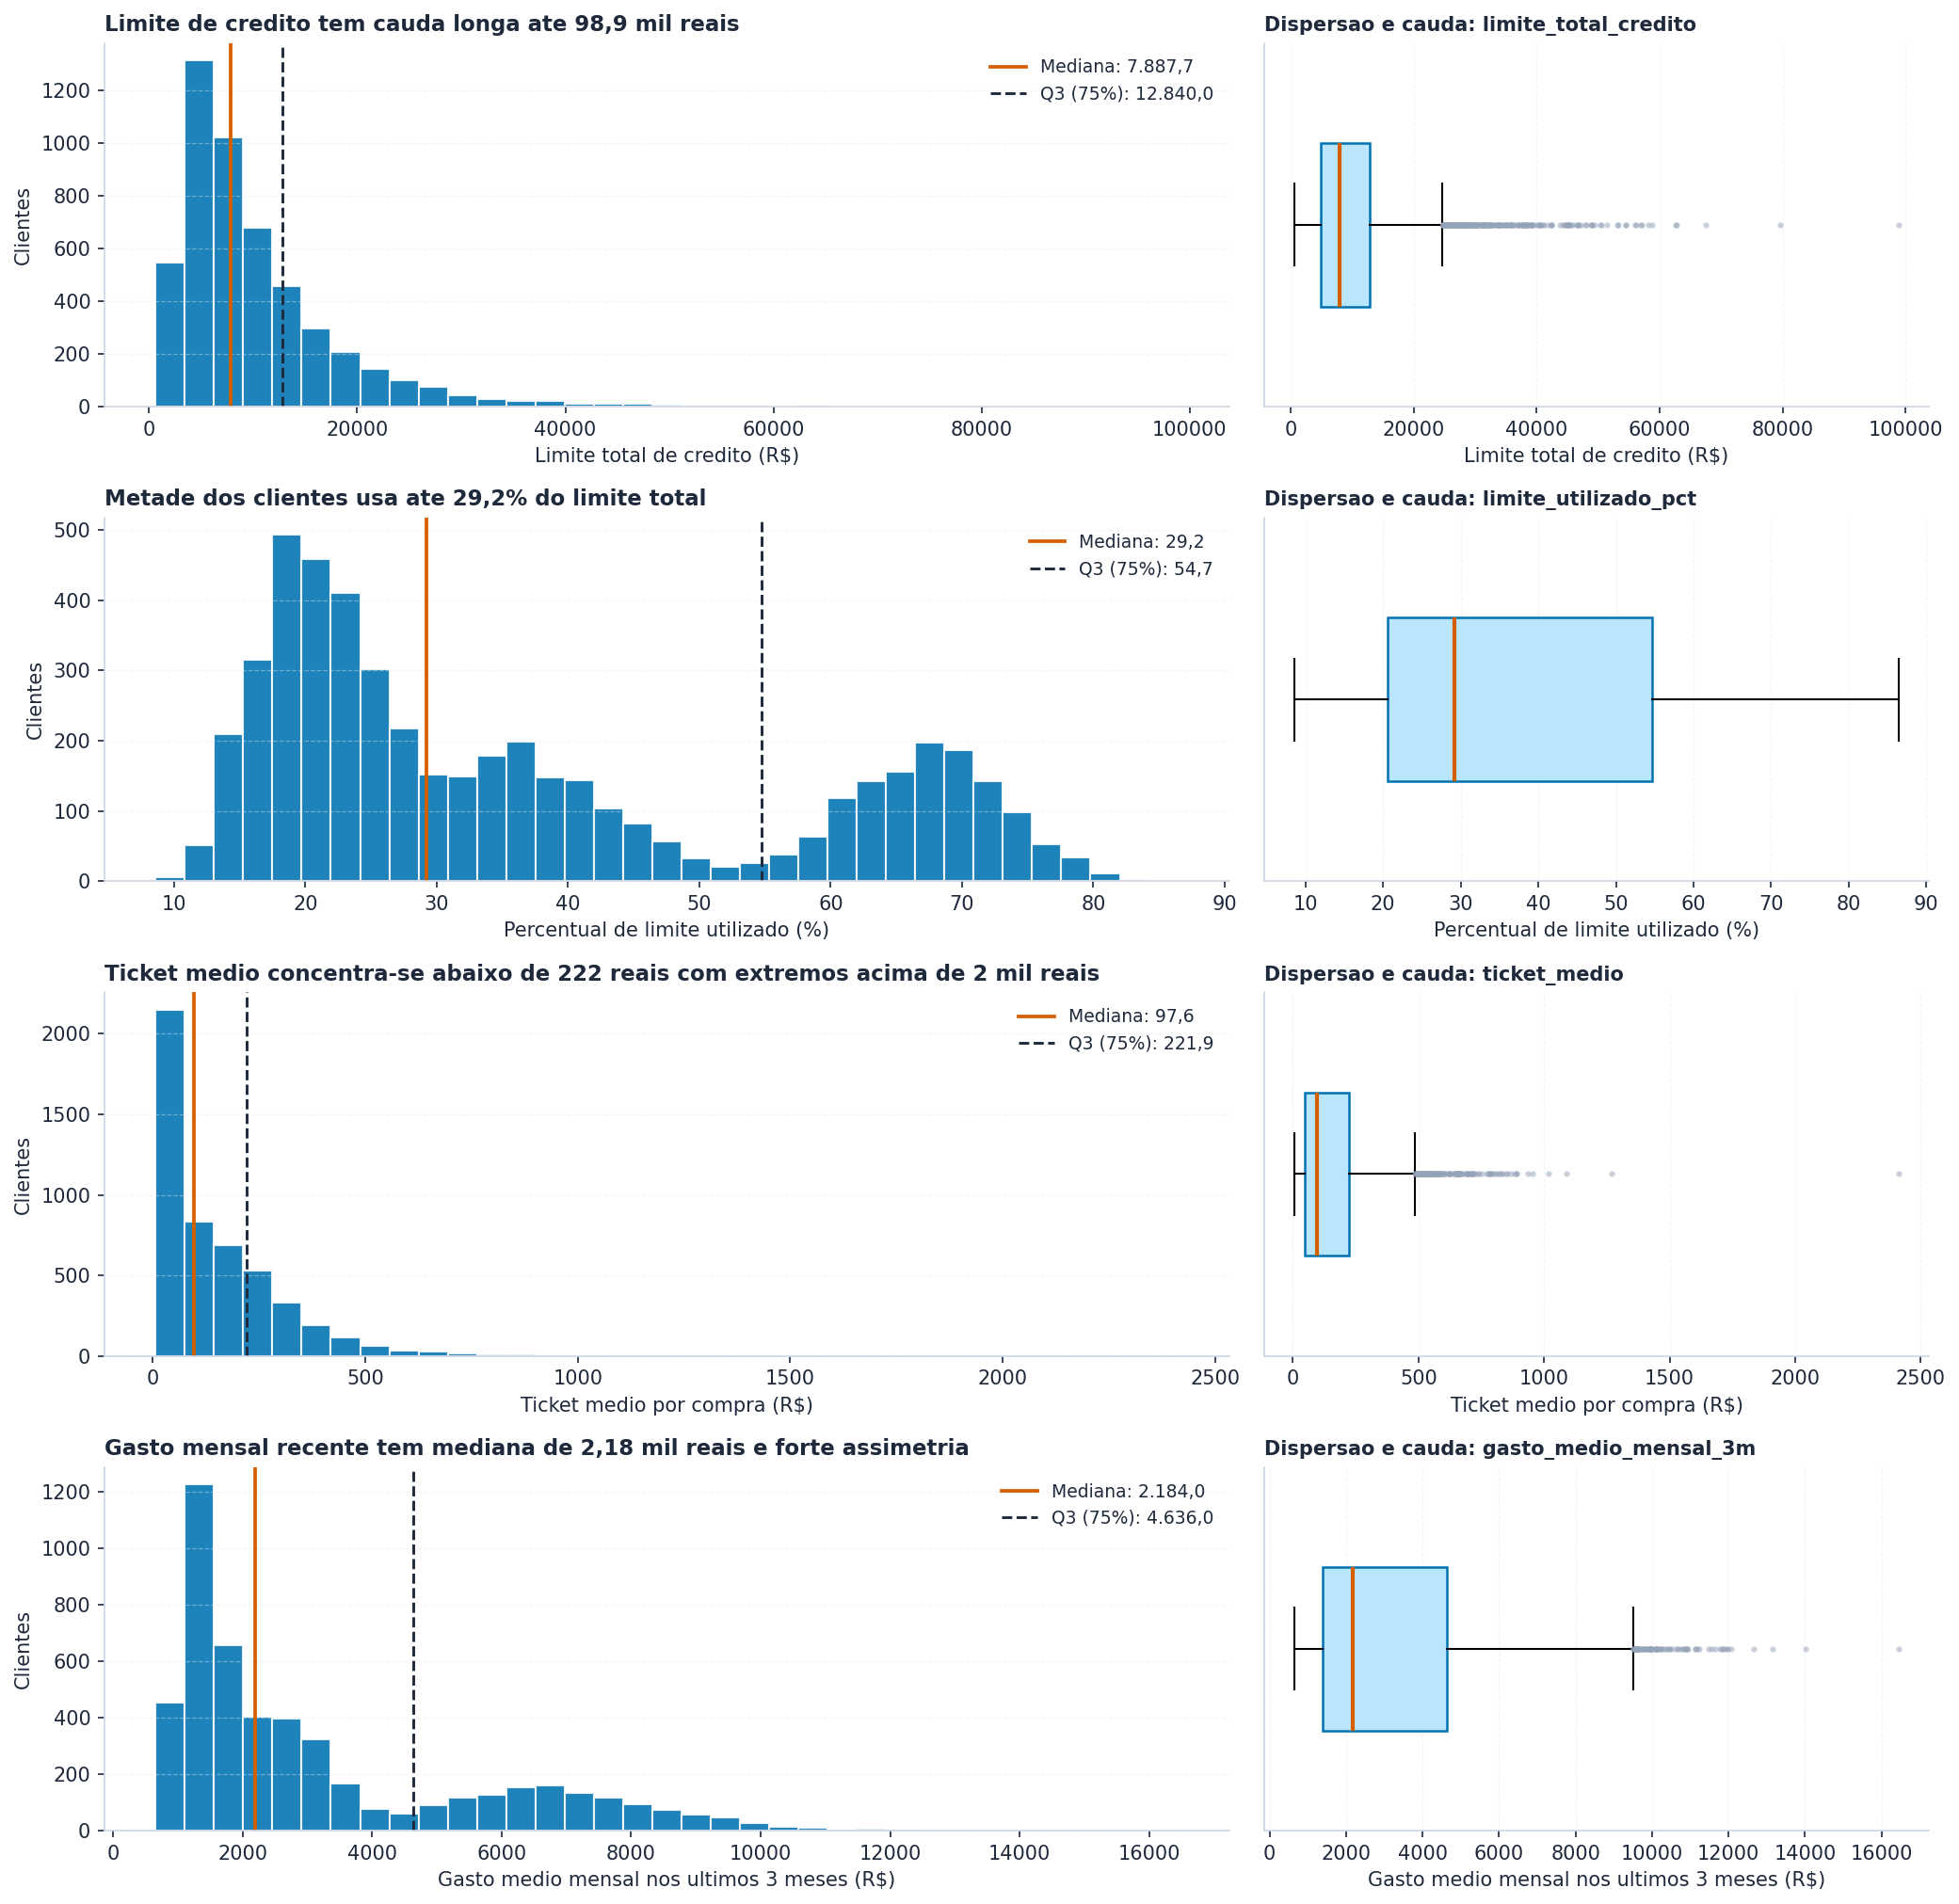

In [4]:
financial_specs = [
    ("limite_total_credito", "Limite de credito tem cauda longa ate 98,9 mil reais", "Limite total de credito (R$)"),
    ("limite_utilizado_pct", "Metade dos clientes usa ate 29,2% do limite total", "Percentual de limite utilizado (%)"),
    ("ticket_medio", "Ticket medio concentra-se abaixo de 222 reais com extremos acima de 2 mil reais", "Ticket medio por compra (R$)"),
    ("gasto_medio_mensal_3m", "Gasto mensal recente tem mediana de 2,18 mil reais e forte assimetria", "Gasto medio mensal nos ultimos 3 meses (R$)"),
]
util.plot_hist_and_box(raw_df, financial_specs, save_path="../reports/figures/fig01_eda_distribuicoes_financeiras.png")

### 3.1 Distribuição das Variáveis Categóricas (Lojista e Canal de Acesso)

Inspecionamos a frequência das categorias de `tipo_lojista_predominante` e `canal_acesso_predominante`. Três setores de consumo cotidiano (`supermercado`, `combustivel` e `restaurante`) concentram $63,5\%$ dos titulares, enquanto compras por aproximação (`contactless`, $46,3\%$) e comércio eletrônico (`web`, $24,7\%$) dominam os canais.

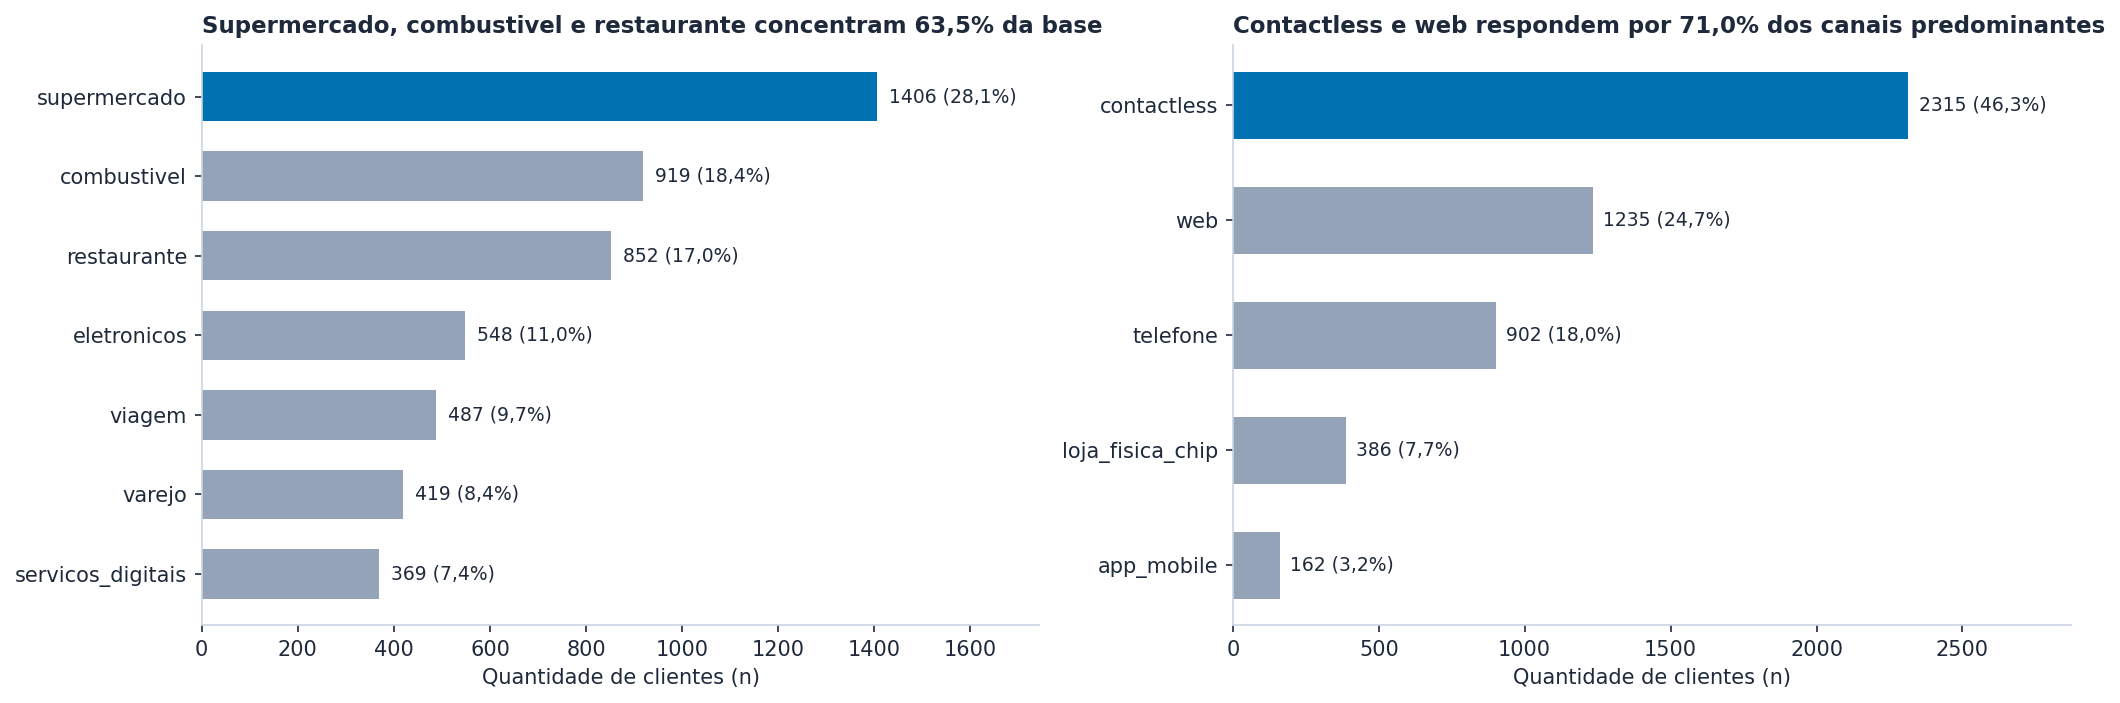

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))

lojista_counts = raw_df["tipo_lojista_predominante"].value_counts().sort_values(ascending=True)
lojista_pct = (lojista_counts / len(raw_df)) * 100
colors_loj = [util.COLOR_NEUTRAL] * (len(lojista_counts) - 1) + [util.COLOR_HIGHLIGHT]
bars1 = axs[0].barh(lojista_counts.index, lojista_counts.values, color=colors_loj, height=0.62)
axs[0].set_title("Supermercado, combustivel e restaurante concentram 63,5% da base", loc="left", fontsize=11)
axs[0].set_xlabel("Quantidade de clientes (n)")
axs[0].set_xlim(0, lojista_counts.max() * 1.24)
for bar, pct in zip(bars1, lojista_pct.values):
    w = bar.get_width()
    axs[0].text(w + 25, bar.get_y() + bar.get_height() / 2, f"{int(w)} ({pct:.1f}%)".replace(".", ","), va="center", fontsize=9)

canal_counts = raw_df["canal_acesso_predominante"].value_counts().sort_values(ascending=True)
canal_pct = (canal_counts / len(raw_df)) * 100
colors_can = [util.COLOR_NEUTRAL] * (len(canal_counts) - 1) + [util.COLOR_HIGHLIGHT]
bars2 = axs[1].barh(canal_counts.index, canal_counts.values, color=colors_can, height=0.58)
axs[1].set_title("Contactless e web respondem por 71,0% dos canais predominantes", loc="left", fontsize=11)
axs[1].set_xlabel("Quantidade de clientes (n)")
axs[1].set_xlim(0, canal_counts.max() * 1.24)
for bar, pct in zip(bars2, canal_pct.values):
    w = bar.get_width()
    axs[1].text(w + 35, bar.get_y() + bar.get_height() / 2, f"{int(w)} ({pct:.1f}%)".replace(".", ","), va="center", fontsize=9)

plt.tight_layout()
fig.savefig("../reports/figures/fig02_eda_categoricas.png")
plt.show()

### 3.2 Relação entre Limite Total, Valor Utilizado e Maturidade da Conta

O gráfico de dispersão abaixo cruza o limite total concedido com o valor efetivamente utilizado, codificando a idade da conta em meses pela cor. Observa-se uma bifurcação clara: clientes mais antigos (acima de 80 meses) detêm limites elevados mas mantêm o valor utilizado contido (abaixo de R\$ 5 mil), ao passo que um grupo de maturidade intermediária (30 a 60 meses) consome entre $60\%$ e $85\%$ do limite total.

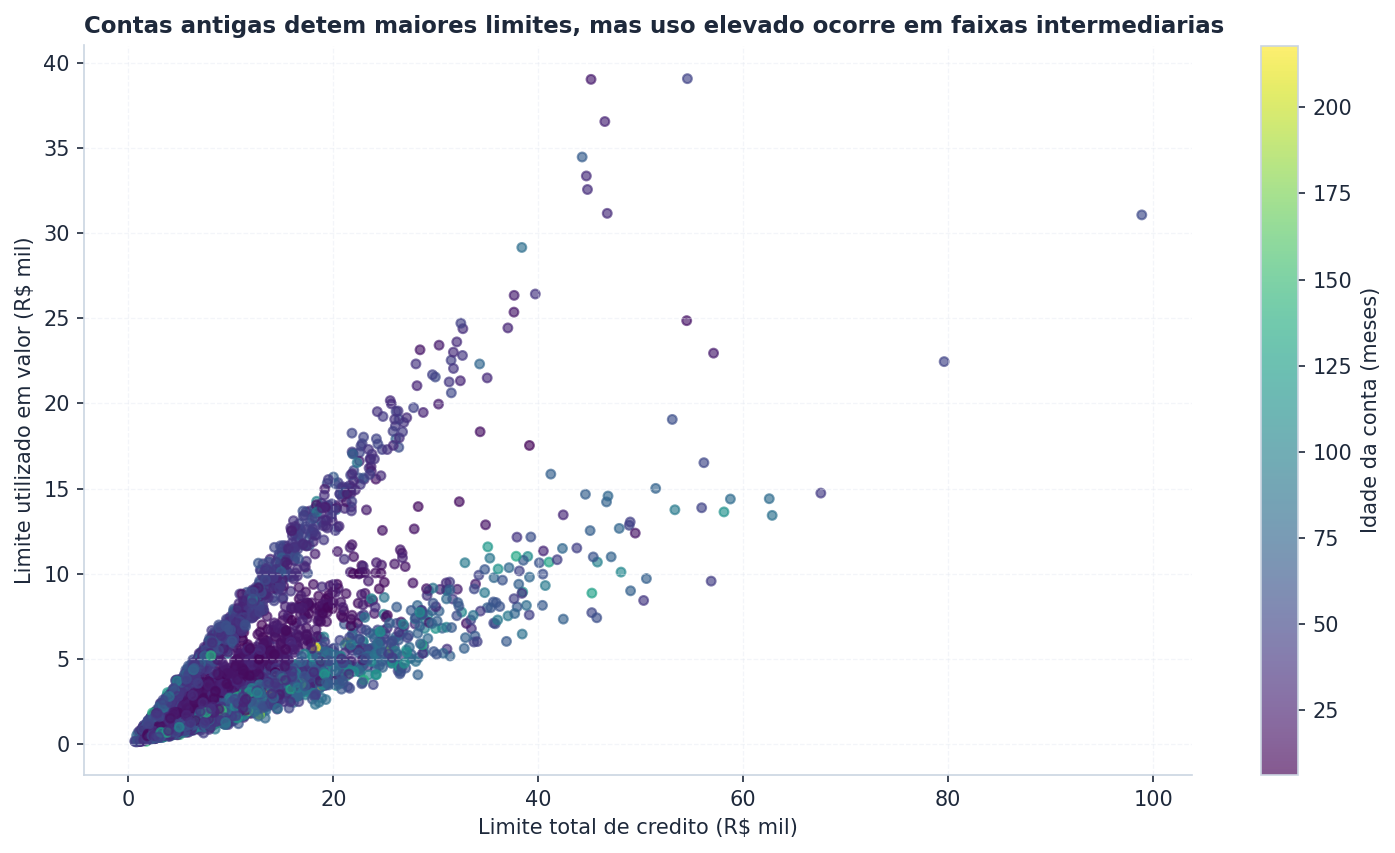

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.8))
scatter = ax.scatter(
    raw_df["limite_total_credito"] / 1000.0,
    raw_df["limite_utilizado_valor"] / 1000.0,
    c=raw_df["idade_conta_meses"],
    cmap="viridis",
    alpha=0.65,
    s=18,
)
cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Idade da conta (meses)")
ax.set_title("Contas antigas detem maiores limites, mas uso elevado ocorre em faixas intermediarias", loc="left", fontsize=11)
ax.set_xlabel("Limite total de credito (R$ mil)")
ax.set_ylabel("Limite utilizado em valor (R$ mil)")
ax.grid(True, alpha=0.4)
plt.tight_layout()
fig.savefig("../reports/figures/fig03_eda_dispersao_limite.png")
plt.show()

### 3.3 Distribuição dos Indicadores Comportamentais de Risco e Fraude

Reutilizamos `util.plot_hist_and_box` para inspecionar as quatro variáveis diretamente associadas a desvios operacionais e suspeitas de fraude: percentual de compras na madrugada, saques no cartão de crédito, quantidade de estornos e alterações cadastrais nos últimos 12 meses.

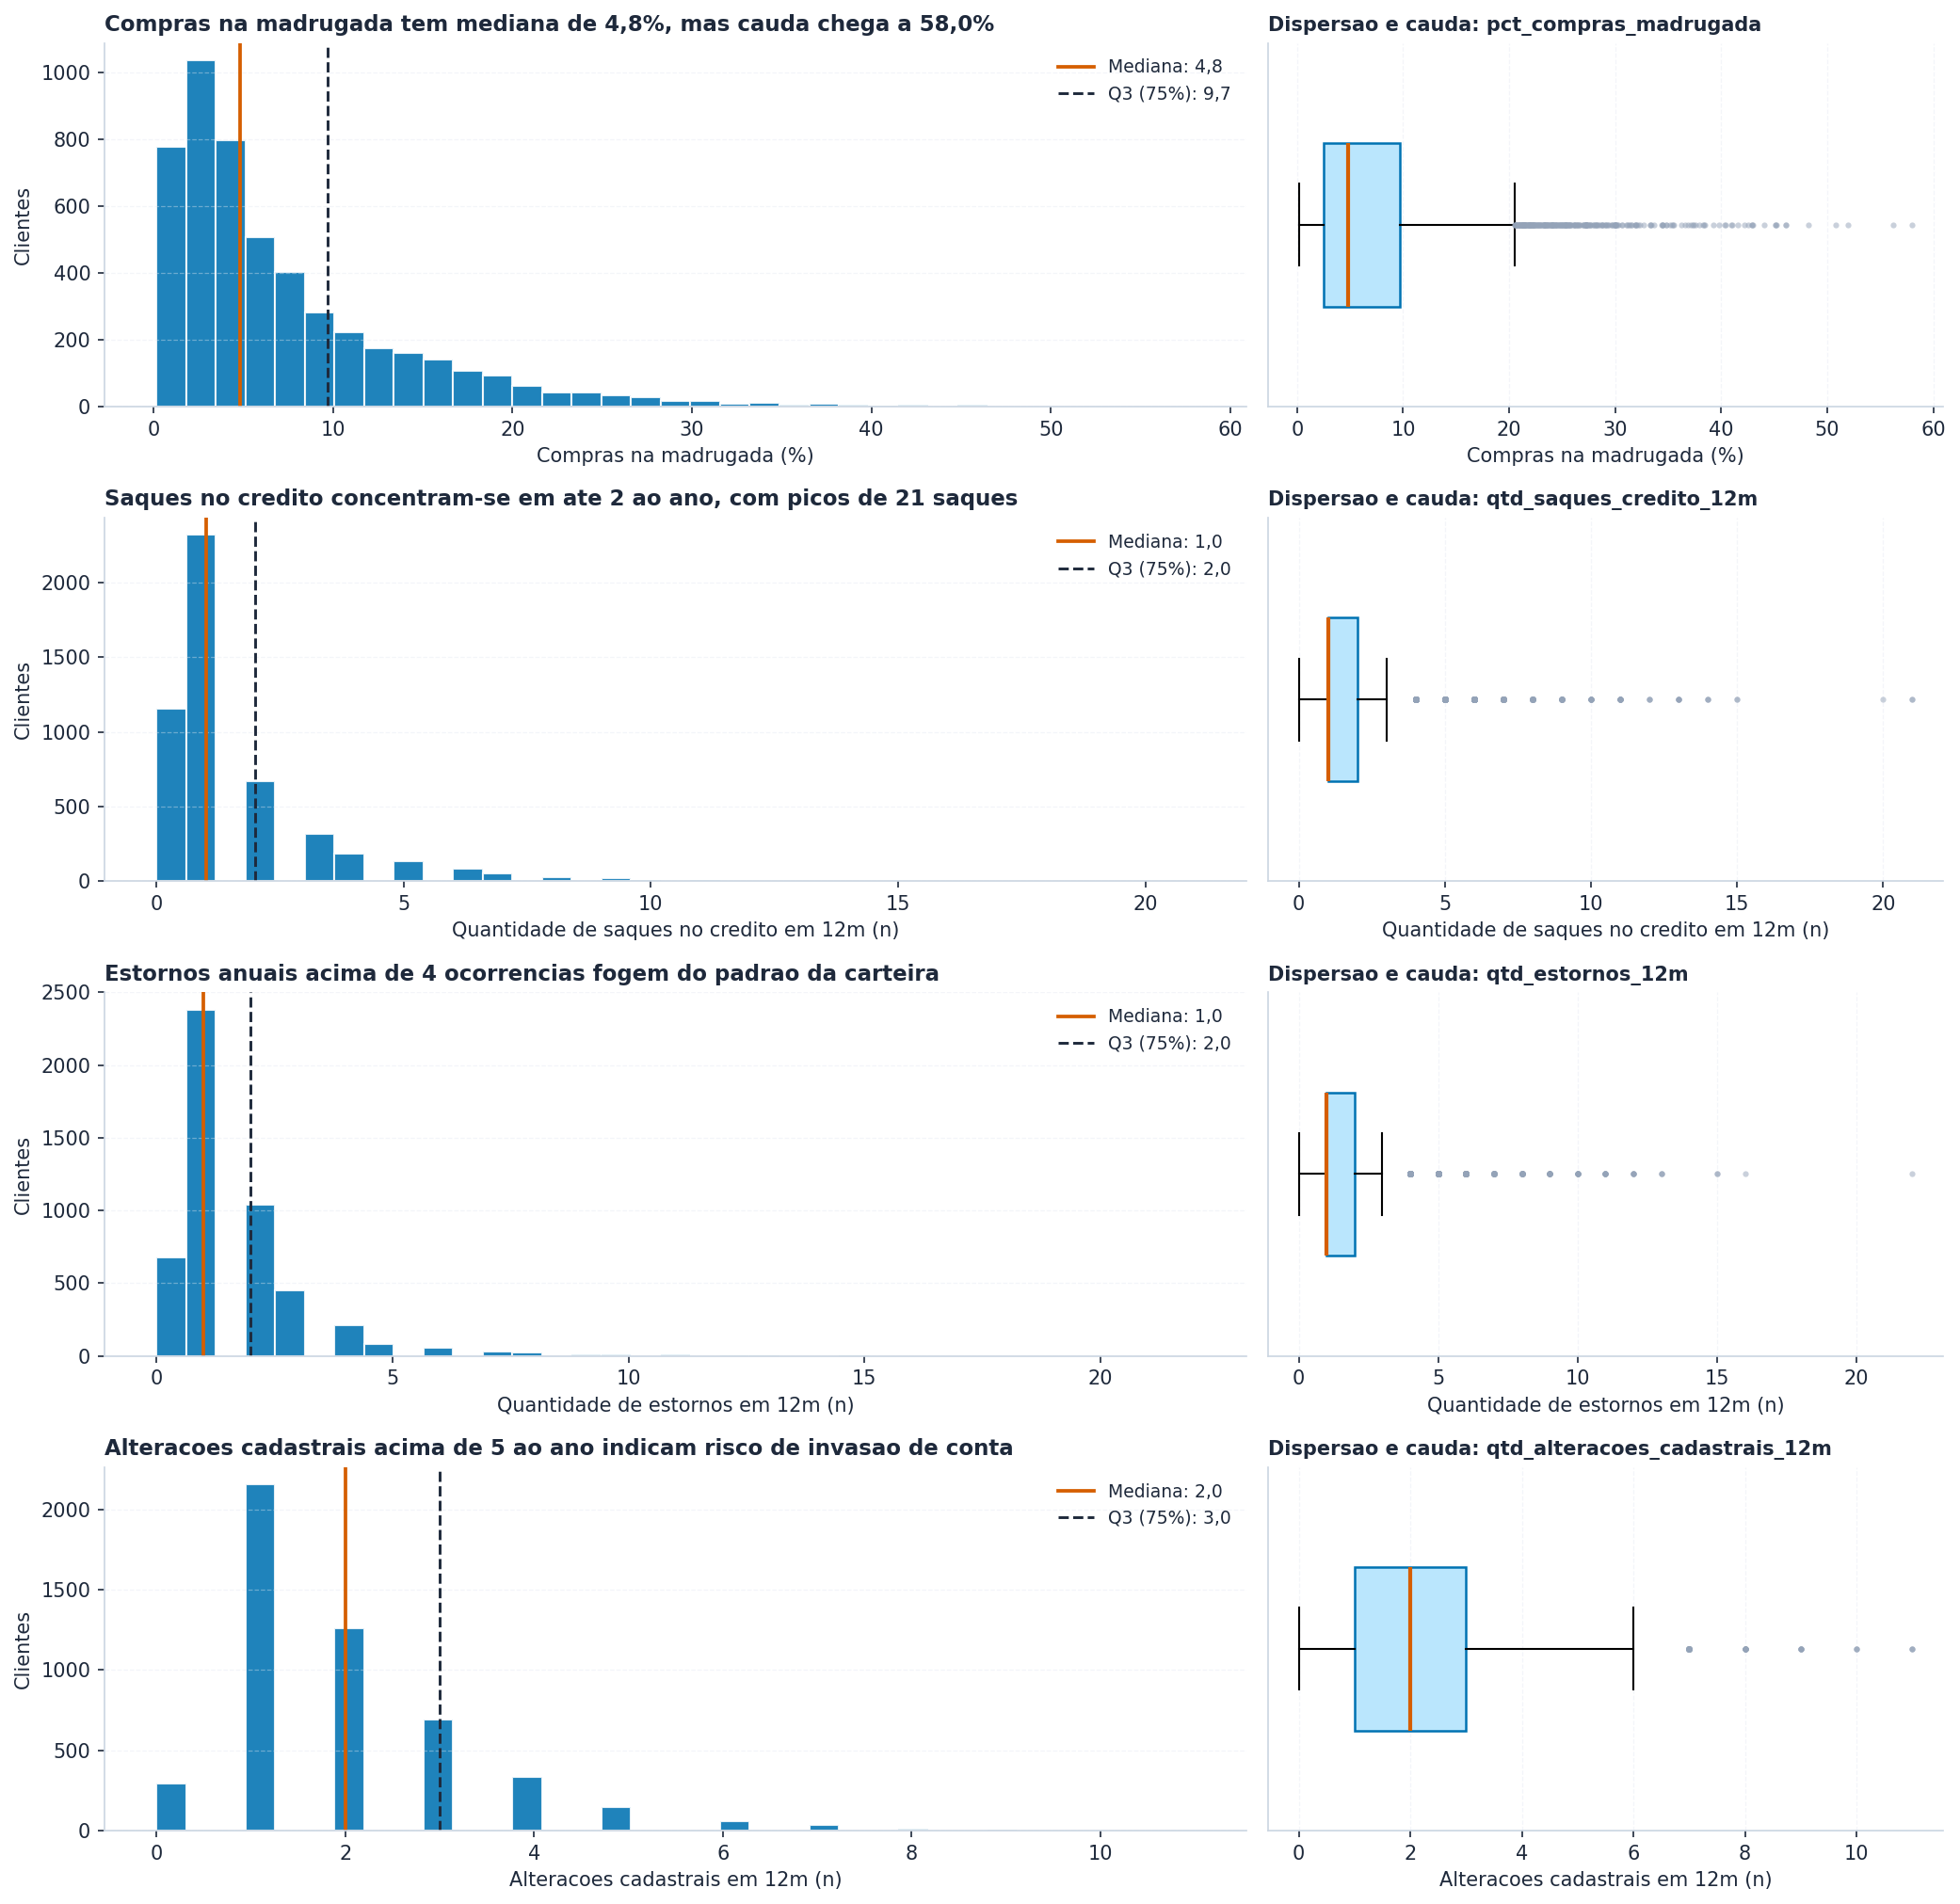

In [7]:
risk_specs = [
    ("pct_compras_madrugada", "Compras na madrugada tem mediana de 4,8%, mas cauda chega a 58,0%", "Compras na madrugada (%)"),
    ("qtd_saques_credito_12m", "Saques no credito concentram-se em ate 2 ao ano, com picos de 21 saques", "Quantidade de saques no credito em 12m (n)"),
    ("qtd_estornos_12m", "Estornos anuais acima de 4 ocorrencias fogem do padrao da carteira", "Quantidade de estornos em 12m (n)"),
    ("qtd_alteracoes_cadastrais_12m", "Alteracoes cadastrais acima de 5 ao ano indicam risco de invasao de conta", "Alteracoes cadastrais em 12m (n)"),
]
util.plot_hist_and_box(raw_df, risk_specs, save_path="../reports/figures/fig04_eda_indicadores_risco.png")

## 4. Etapas de Pré-processamento e Transformação (KDD)

### 4.1 Codificação de Variáveis Categóricas com One-Hot Encoding

Removemos a coluna identificadora `id_cliente` e convertemos as variáveis categóricas `tipo_lojista_predominante` (7 categorias) e `canal_acesso_predominante` (5 categorias) em variáveis binárias ($0$ ou $1$) por meio do **One-Hot Encoding** (`pd.get_dummies`).

#### O que escolhemos e por que não escolhemos outra técnica
- **Por que escolhemos One-Hot Encoding**: As categorias de lojista (`supermercado`, `combustivel`, `restaurante`, `eletronicos`, `viagem`, `varejo`, `servicos_digitais`) e de canal (`contactless`, `web`, `telefone`, `loja_fisica_chip`, `app_mobile`) são atributos **categóricos nominais**. Não existe hierarquia nem ordem intrínseca entre eles. O One-Hot Encoding cria coordenadas ortogonais binárias equidistantes, permitindo que a predominância de um canal ou setor componha o perfil do grupo sem distorcer as distâncias.
- **Por que NÃO escolhemos `LabelEncoder` ou `OrdinalEncoder`**: A codificação ordinal atribui números inteiros sequenciais ($0, 1, 2, \dots, 6$) a cada categoria. Como K-Means, DBSCAN e GMM baseiam-se em distâncias euclidianas e covariâncias no espaço contínuo, atribuir `supermercado = 0`, `combustivel = 1` e `viagem = 6` faria o modelo assumir matematicamente que `viagem` está seis vezes mais distante de `supermercado` do que `combustivel`, além de supor que a média entre `supermercado` ($0$) e `viagem` ($6$) é `eletronicos` ($3$).
- **Por que NÃO escolhemos `TargetEncoder`**: Técnicas de codificação supervisionada dependem de uma variável-alvo rotulada ($y$, como fraude confirmada), inexistente em problemas de aprendizado não supervisionado.

In [8]:
categorical_cols = ["tipo_lojista_predominante", "canal_acesso_predominante"]
numeric_cols = [c for c in raw_df.columns if c not in categorical_cols + ["id_cliente"]]

df_no_id = raw_df.drop(columns=["id_cliente"])
df_encoded = pd.get_dummies(df_no_id, columns=categorical_cols, drop_first=False, dtype=int)

print(f"Dimensao original: {raw_df.shape}")
print(f"Dimensao apos remocao de id_cliente e One-Hot Encoding: {df_encoded.shape}")
df_encoded.head()

Dimensao original: (5000, 37)
Dimensao apos remocao de id_cliente e One-Hot Encoding: (5000, 46)


,limite_total_credito,limite_utilizado_pct,gasto_medio_mensal_3m,gasto_medio_mensal_12m,gasto_maximo_unico,qtd_transacoes_30d,qtd_transacoes_90d,qtd_estornos_12m,valor_estornos_12m,taxa_estorno_pct,qtd_atrasos_12m,dias_desde_ultimo_atraso,pct_pagamento_minimo,pct_pagamento_total_fatura,qtd_parcelamentos_12m,pct_compras_parceladas,pct_compras_online,pct_compras_internacionais,pct_compras_madrugada,pct_compras_fim_de_semana,qtd_lojistas_distintos_30d,qtd_categorias_distintas_30d,qtd_dispositivos_distintos_90d,qtd_cidades_distintas_30d,qtd_saques_credito_12m,valor_saques_credito_12m,idade_conta_meses,qtd_cartoes_adicionais,qtd_contestacoes_12m,qtd_alteracoes_cadastrais_12m,score_interno_comportamental,pct_limite_comprometido_parcelas,limite_utilizado_valor,ticket_medio,tipo_lojista_predominante_combustivel,tipo_lojista_predominante_eletronicos,tipo_lojista_predominante_restaurante,tipo_lojista_predominante_servicos_digitais,tipo_lojista_predominante_supermercado,tipo_lojista_predominante_varejo,tipo_lojista_predominante_viagem,canal_acesso_predominante_app_mobile,canal_acesso_predominante_contactless,canal_acesso_predominante_loja_fisica_chip,canal_acesso_predominante_telefone,canal_acesso_predominante_web
0,11129.63,20.50,1265.50,1071.28,3410.39,25,67,1,88.65,6.75,2,84,12.69,87.90,2,58.91,76.95,2.10,2.46,41.48,6,6,4,3,5,578.37,80,3,1,1,742.29,4.69,2281.60,50.62,0,0,1,0,0,0,0,0,1,0,0,0
1,9484.15,66.95,6423.95,6344.41,652.86,17,49,1,486.59,1.05,0,392,11.49,52.46,8,22.03,49.05,19.30,6.82,49.19,22,3,1,2,0,67.76,43,2,0,1,484.21,32.44,6349.72,377.88,1,0,0,0,0,0,0,0,1,0,0,0
2,7464.09,21.71,1620.24,1413.21,2779.16,40,120,1,126.94,4.65,2,63,21.23,89.27,2,60.41,71.98,3.40,1.31,50.61,7,7,3,1,2,1007.40,102,2,2,1,725.86,7.55,1620.48,40.51,0,0,1,0,0,0,0,0,0,0,0,1
3,3450.89,16.00,1306.73,1184.46,1675.44,54,158,2,528.70,4.88,1,308,29.23,54.81,2,24.80,21.10,2.83,6.63,18.94,12,12,2,4,1,490.07,46,0,2,4,545.90,11.92,552.07,24.20,0,0,0,0,0,1,0,0,1,0,0,0
4,17351.53,78.55,8664.67,7804.27,866.47,15,42,2,420.21,1.01,0,251,10.55,55.34,17,20.32,53.48,34.40,3.58,44.73,21,3,1,2,1,56.01,32,2,0,1,503.08,41.87,13630.45,577.64,0,0,0,0,0,0,1,0,1,0,0,0


### 4.2 Matriz de Correlação e Seleção de Atributos (Eliminação de Multicolinearidade)

A base `base04_cartao_alta_dimensao.csv` possui alta dimensionalidade (34 atributos numéricos + 12 binários = 46 colunas). Calculamos e plotamos a matriz de correlação de Pearson sobre as variáveis numéricas para diagnosticar redundâncias lineares antes da redução dimensional.

#### O que escolhemos e por que não mantivemos as variáveis colineares
- **O que escolhemos**: Definimos o limiar de corte $|r| > 0,90$ para eliminar variáveis numéricas altamente colineares, removendo 8 atributos redundantes (`gasto_medio_mensal_3m`, `gasto_medio_mensal_12m`, `qtd_transacoes_90d`, `taxa_estorno_pct`, `qtd_atrasos_12m`, `pct_compras_internacionais`, `qtd_dispositivos_distintos_90d` e `pct_limite_comprometido_parcelas`) cujas informações já estão integralmente representadas por `limite_utilizado_pct`, `qtd_transacoes_30d`, `gasto_maximo_unico`, `pct_compras_parceladas` e `qtd_lojistas_distintos_30d`.
- **Por que NÃO mantivemos todas as 34 variáveis numéricas**: Variáveis como `gasto_medio_mensal_3m` e `gasto_medio_mensal_12m` apresentam correlação $r = 0,9862$, e `qtd_transacoes_30d` com `qtd_transacoes_90d` apresentam $r = 0,9858$. Se mantivéssemos esses pares, o mesmo fator latente seria somado repetidas vezes na distância euclidiana, atribuindo peso desproporcional ao volume de transações e mascarando variáveis independentes de auditoria de fraude (como `qtd_alteracoes_cadastrais_12m` e `pct_compras_madrugada`).

Variaveis removidas por alta correlacao (|r| > 0,90) [8]: ['gasto_medio_mensal_3m', 'gasto_medio_mensal_12m', 'qtd_transacoes_90d', 'taxa_estorno_pct', 'qtd_atrasos_12m', 'pct_compras_internacionais', 'qtd_dispositivos_distintos_90d', 'pct_limite_comprometido_parcelas']
Variaveis numericas mantidas: 26 | Total de colunas na base: 38


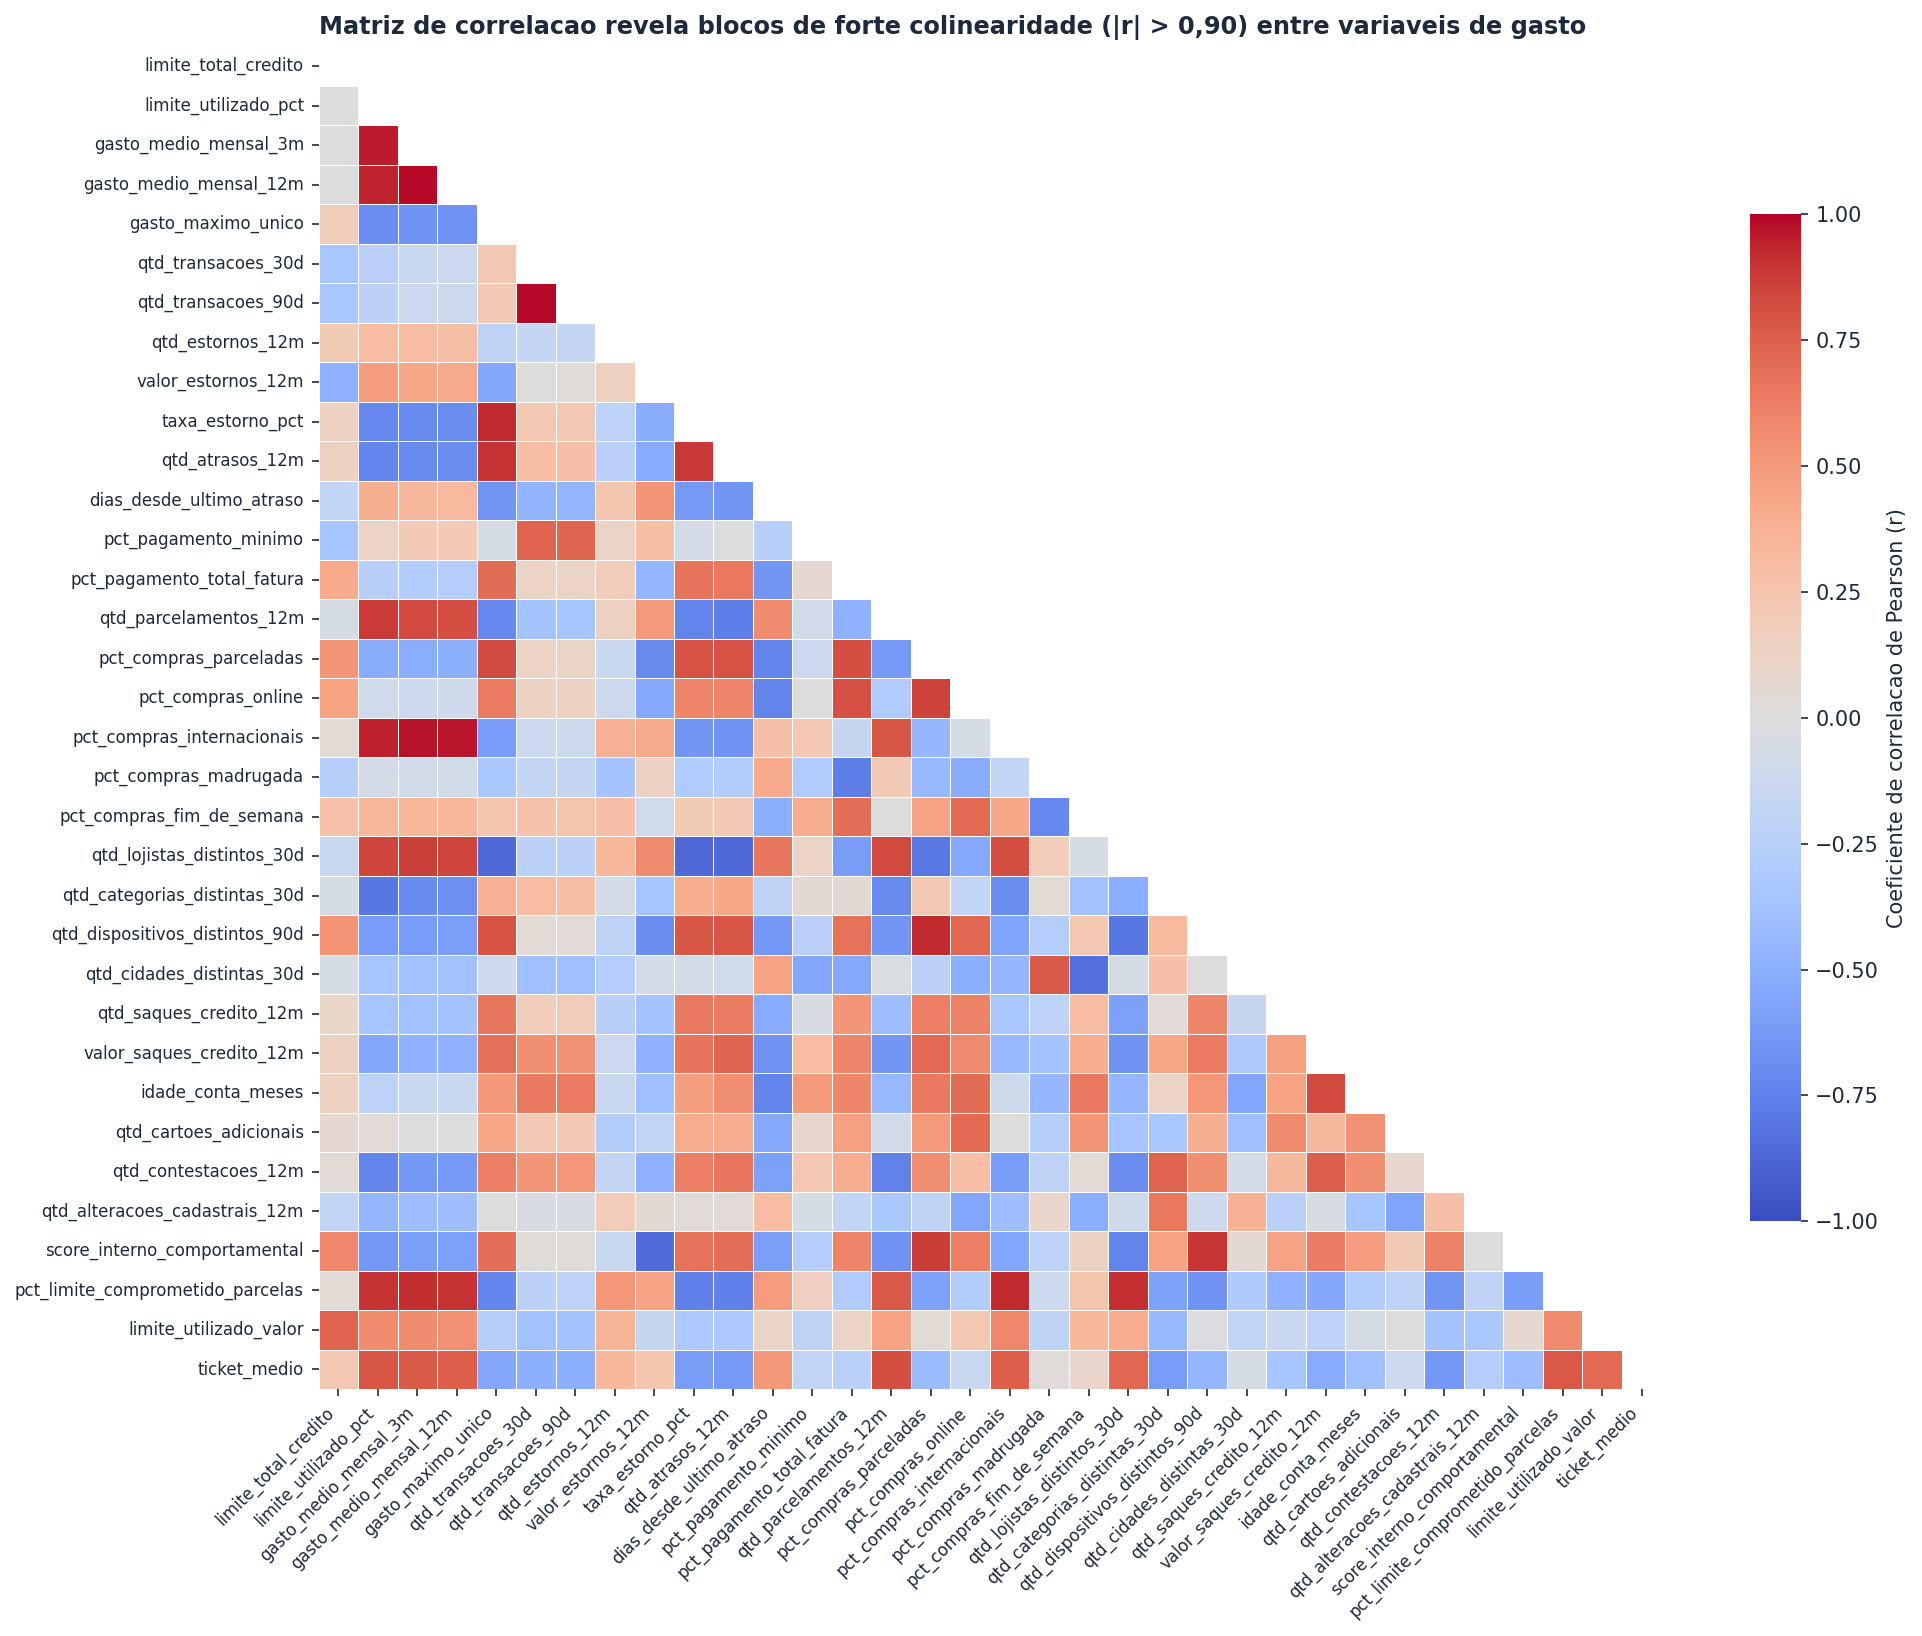

,variavel_1,variavel_2_removida,correlacao_abs
0,gasto_medio_mensal_3m,gasto_medio_mensal_12m,0.9862
1,qtd_transacoes_30d,qtd_transacoes_90d,0.9858
2,gasto_medio_mensal_3m,pct_compras_internacionais,0.9749
3,gasto_medio_mensal_12m,pct_compras_internacionais,0.9625
4,limite_utilizado_pct,gasto_medio_mensal_3m,0.9581
5,limite_utilizado_pct,pct_compras_internacionais,0.9454
6,limite_utilizado_pct,gasto_medio_mensal_12m,0.9428
7,gasto_maximo_unico,taxa_estorno_pct,0.9251
8,pct_compras_parceladas,qtd_dispositivos_distintos_90d,0.9249
9,pct_compras_internacionais,pct_limite_comprometido_parcelas,0.9220


In [9]:
corr_matrix = df_encoded[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
mask_triu = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask_triu,
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    center=0.0,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.75, "label": "Coeficiente de correlacao de Pearson (r)"},
    ax=ax,
)
ax.set_title("Matriz de correlacao revela blocos de forte colinearidade (|r| > 0,90) entre variaveis de gasto", loc="left", fontsize=11.5)
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
fig.savefig("../reports/figures/fig05_matriz_correlacao.png")
plt.show()

corr_abs = corr_matrix.abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

high_corr_pairs = []
for col in upper_tri.columns:
    for row in upper_tri.index:
        val = upper_tri.loc[row, col]
        if pd.notnull(val) and val > 0.90:
            high_corr_pairs.append({"variavel_1": row, "variavel_2_removida": col, "correlacao_abs": round(float(val), 4)})

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values(by="correlacao_abs", ascending=False).reset_index(drop=True)
dropped_corr_cols = [col for col in upper_tri.columns if any(upper_tri[col] > 0.90)]
kept_numeric_cols = [c for c in numeric_cols if c not in dropped_corr_cols]
df_reduced_cols = df_encoded.drop(columns=dropped_corr_cols).copy()

print(f"Variaveis removidas por alta correlacao (|r| > 0,90) [{len(dropped_corr_cols)}]: {dropped_corr_cols}")
print(f"Variaveis numericas mantidas: {len(kept_numeric_cols)} | Total de colunas na base: {df_reduced_cols.shape[1]}")
high_corr_df

### 4.3 Análise e Remoção de Outliers Extremos

Analisamos a presença de outliers univariados nas 26 variáveis numéricas remanescentes para evitar que distorções extremas desloquem os eixos de variância do PCA e os centróides dos algoritmos de agrupamento.

#### O que escolhemos e por que não escolhemos outra regra de corte
- **O que escolhemos**: Aplicamos o filtro de outliers extremos baseado em **$4,0 \times \text{IQR}$** ($[Q_1 - 4,0 \cdot \text{IQR},\; Q_3 + 4,0 \cdot \text{IQR}]$). Esse critério identifica e remove **356 registros** ($7,12\%$ da base) que possuem valores univariados aberrantes (por exemplo, limites próximos a R\$ 99 mil combinados com 21 saques no crédito), preservando **4.644 clientes** para a modelagem comparativa. Os 356 registros removidos são salvos separadamente para auditoria direta de risco extremo.
- **Por que NÃO usamos a regra padrão de $1,5 \times \text{IQR}$**: Em bases financeiras multidimensionais com distribuições assimétricas à direita, aplicar $1,5 \times \text{IQR}$ simultaneamente em 26 variáveis eliminaria **2.221 clientes ($44,42\%$ da base total)**, destruindo a representatividade da carteira e apagando quase metade dos clientes legítimos.
- **Por que NÃO usamos Z-Score ($|z| > 3$)**: O cálculo do Z-Score utiliza média e desvio-padrão, que são altamente inflados pelos próprios valores extremos da cauda longa, gerando o chamado *efeito de mascaramento* (onde um outlier extremo infla o desvio-padrão e impede a detecção de outros outliers).

In [10]:
q1 = df_reduced_cols[kept_numeric_cols].quantile(0.25)
q3 = df_reduced_cols[kept_numeric_cols].quantile(0.75)
iqr = q3 - q1

low_15 = q1 - 1.5 * iqr
high_15 = q3 + 1.5 * iqr
low_40 = q1 - 4.0 * iqr
high_40 = q3 + 4.0 * iqr

outlier_rows = []
for col in kept_numeric_cols:
    c_15 = int(((df_reduced_cols[col] < low_15[col]) | (df_reduced_cols[col] > high_15[col])).sum())
    c_40 = int(((df_reduced_cols[col] < low_40[col]) | (df_reduced_cols[col] > high_40[col])).sum())
    outlier_rows.append({
        "variavel": col,
        "mediana": round(float(df_reduced_cols[col].median()), 2),
        "iqr": round(float(iqr[col]), 2),
        "limite_superior_4_iqr": round(float(high_40[col]), 2),
        "outliers_1_5_iqr": c_15,
        "outliers_extremos_4_0_iqr": c_40,
    })

outlier_report_df = pd.DataFrame(outlier_rows).sort_values(by="outliers_extremos_4_0_iqr", ascending=False).reset_index(drop=True)

extreme_outlier_mask = ((df_reduced_cols[kept_numeric_cols] < low_40) | (df_reduced_cols[kept_numeric_cols] > high_40)).any(axis=1)
df_no_outliers = df_reduced_cols[~extreme_outlier_mask].copy().reset_index(drop=True)
df_orig_valid = raw_df[~extreme_outlier_mask].copy().reset_index(drop=True)
df_orig_extreme_outliers = raw_df[extreme_outlier_mask].copy().reset_index(drop=True)

print(f"Registros originais: {len(raw_df)}")
print(f"Outliers univariados extremos removidos (4,0 x IQR): {int(extreme_outlier_mask.sum())} ({extreme_outlier_mask.mean()*100:.2f}%)")
print(f"Registros retidos para escalonamento e clusterizacao: {len(df_no_outliers)} ({len(df_no_outliers)/len(raw_df)*100:.2f}%)")
outlier_report_df.head(12)

Registros originais: 5000
Outliers univariados extremos removidos (4,0 x IQR): 356 (7.12%)
Registros retidos para escalonamento e clusterizacao: 4644 (92.88%)


,variavel,mediana,iqr,limite_superior_4_iqr,outliers_1_5_iqr,outliers_extremos_4_0_iqr
0,qtd_saques_credito_12m,1.00,1.00,6.00,538,136
1,qtd_estornos_12m,1.00,1.00,6.00,447,93
2,limite_utilizado_valor,2584.90,3458.30,18659.99,326,49
3,limite_total_credito,7887.74,7947.87,44631.50,273,38
4,pct_compras_madrugada,4.82,7.21,38.55,275,23
5,valor_saques_credito_12m,183.62,371.81,1946.13,233,20
6,valor_estornos_12m,349.61,417.25,2248.96,169,9
7,qtd_cartoes_adicionais,1.00,1.00,6.00,171,9
8,ticket_medio,97.56,176.40,927.45,166,6
9,qtd_transacoes_30d,25.00,17.00,103.00,185,5


### 4.4 Normalização com `RobustScaler` e Reavaliação Gráfica Pós-Processamento

As variáveis numéricas possuem unidades e ordens de grandeza incompatíveis: `limite_total_credito` é medido em dezenas de milhares de reais, `score_interno_comportamental` varia na casa das centenas e `qtd_contestacoes_12m` varia de $0$ a $4$. Sem escalonamento, qualquer cálculo de distância euclidiana seria dominado exclusivamente pelo limite de crédito.

#### O que escolhemos e por que não escolhemos outro escalonador
- **Por que escolhemos `RobustScaler`**: Ele subtrai a **mediana** e divide pelo **Intervalo Interquartil ($\text{IQR} = Q_3 - Q_1$)** de cada variável:
  $$x_{\text{scaled}} = \frac{x - \text{Mediana}(x)}{Q_3(x) - Q_1(x)}$$
  Como a mediana e os quartis são estatísticas de ordem imunes à assimetria residual das caudas, todas as variáveis passam a ter centro em $0$ e dispersão interquartil unitária, preservando as distâncias relativas reais entre os clientes.
- **Por que NÃO escolhemos `MinMaxScaler`**: O `MinMaxScaler` comprime os dados no intervalo $[0, 1]$ usando os valores mínimo e máximo absolutos. Em variáveis financeiras como `limite_total_credito` ou `limite_utilizado_valor`, a presença de clientes com limites elevados no topo da distribuição esmagaria os valores pequenos e médios (que representam a grande maioria da carteira) em uma faixa minúscula próxima de zero, anulando o poder discriminativo entre perfis de varejo e perfis intermediários.
- **Por que NÃO escolhemos `StandardScaler`**: Embora centralize pela média e escale pelo desvio-padrão, variáveis de contagem como `qtd_saques_credito_12m`, `qtd_estornos_12m` e `pct_compras_madrugada` continuam assimétricas mesmo após o filtro de extremos. A média e a variância sofrem deslocamento na direção da cauda direita, distorcendo a escala frente a variáveis simétricas como `pct_pagamento_total_fatura`.

Após o `RobustScaler`, plotamos novamente os boxplots comparativos e as distribuições escalonadas para verificar a harmonização das escalas.

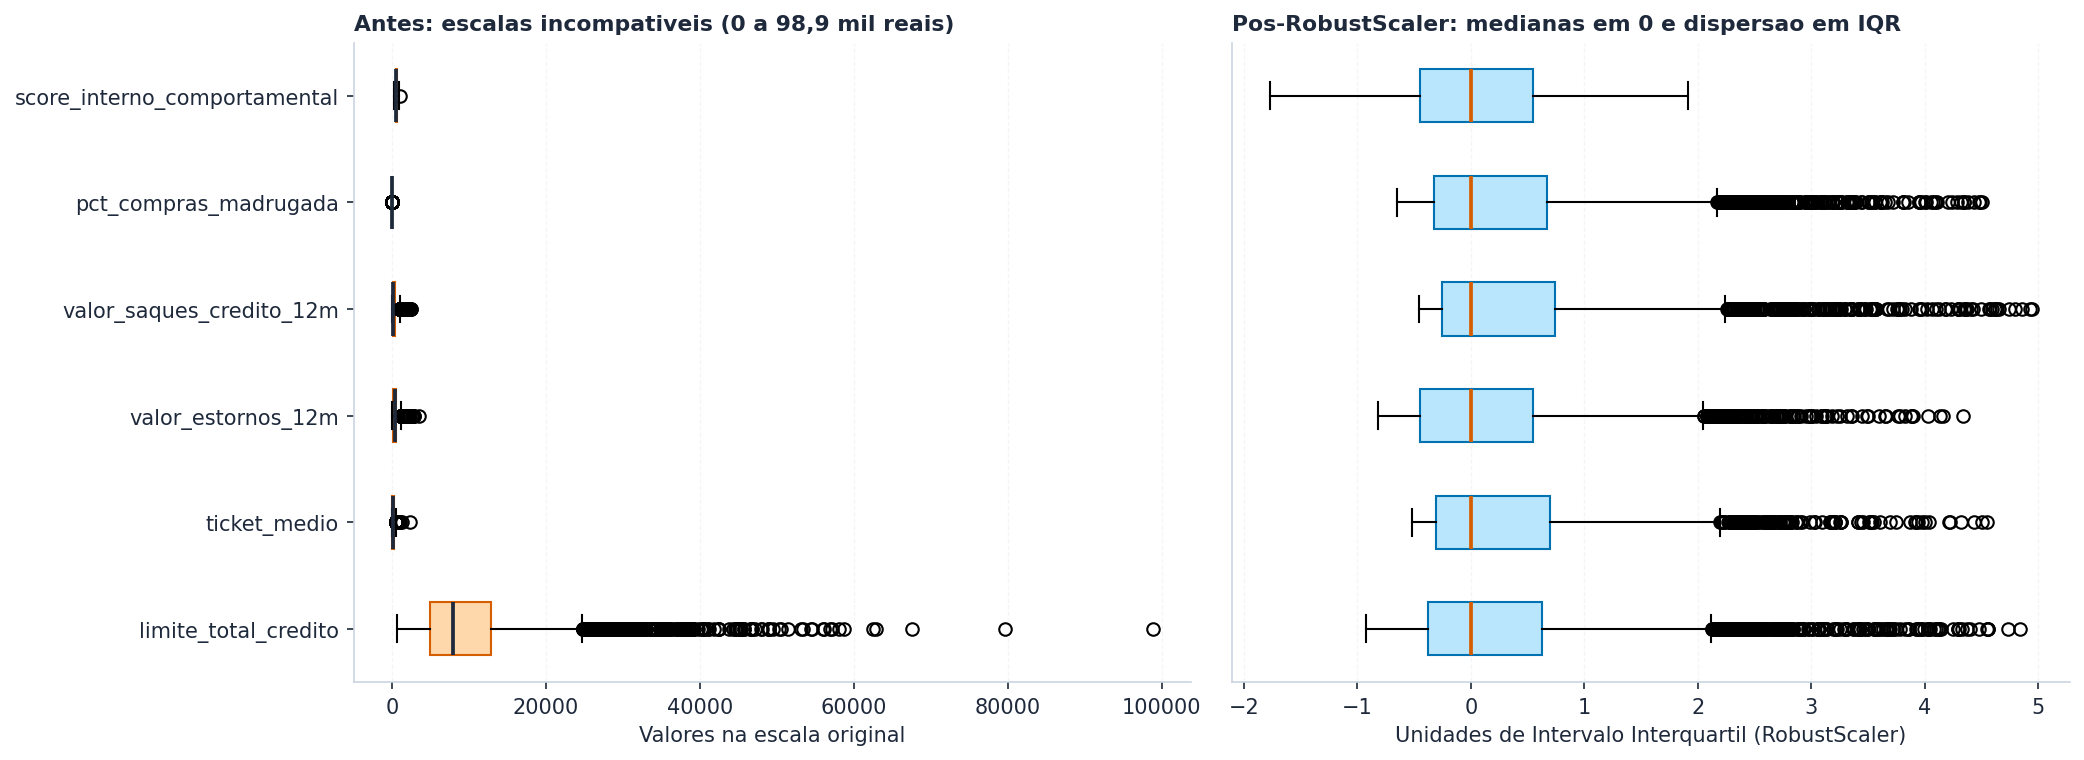

In [11]:
robust_scaler = RobustScaler()
df_scaled = df_no_outliers.copy()
df_scaled[kept_numeric_cols] = robust_scaler.fit_transform(df_no_outliers[kept_numeric_cols])

compare_cols = [
    "limite_total_credito",
    "ticket_medio",
    "valor_estornos_12m",
    "valor_saques_credito_12m",
    "pct_compras_madrugada",
    "score_interno_comportamental",
]

fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))
axs[0].boxplot(
    [raw_df[c] for c in compare_cols],
    vert=False,
    tick_labels=compare_cols,
    patch_artist=True,
    boxprops={"facecolor": "#FED7AA", "edgecolor": util.COLOR_ALERT},
    medianprops={"color": util.COLOR_DARK, "linewidth": 1.8},
)
axs[0].set_title("Antes: escalas incompativeis (0 a 98,9 mil reais)", loc="left", fontsize=10.5)
axs[0].set_xlabel("Valores na escala original")
axs[0].grid(axis="x", alpha=0.4)

axs[1].boxplot(
    [df_scaled[c] for c in compare_cols],
    vert=False,
    tick_labels=compare_cols,
    patch_artist=True,
    boxprops={"facecolor": "#BAE6FD", "edgecolor": util.COLOR_HIGHLIGHT},
    medianprops={"color": util.COLOR_ALERT, "linewidth": 1.8},
)
axs[1].set_title("Pos-RobustScaler: medianas em 0 e dispersao em IQR", loc="left", fontsize=10.5)
axs[1].set_xlabel("Unidades de Intervalo Interquartil (RobustScaler)")
axs[1].set_yticks([])
axs[1].grid(axis="x", alpha=0.4)

plt.tight_layout()
fig.savefig("../reports/figures/fig06_comparacao_robust_scaler.png")
plt.show()

Reutilizamos também `util.plot_hist_and_box` sobre os dados pós-pré-processamento (sem outliers extremos e padronizados pelo `RobustScaler`) para confirmar que as medianas estão centradas em zero e as caudas extremas foram controladas, salvando a base limpa na pasta `data/`.

Bases limpas salvas em data/base04_cartao_limpa.csv e data/processed/


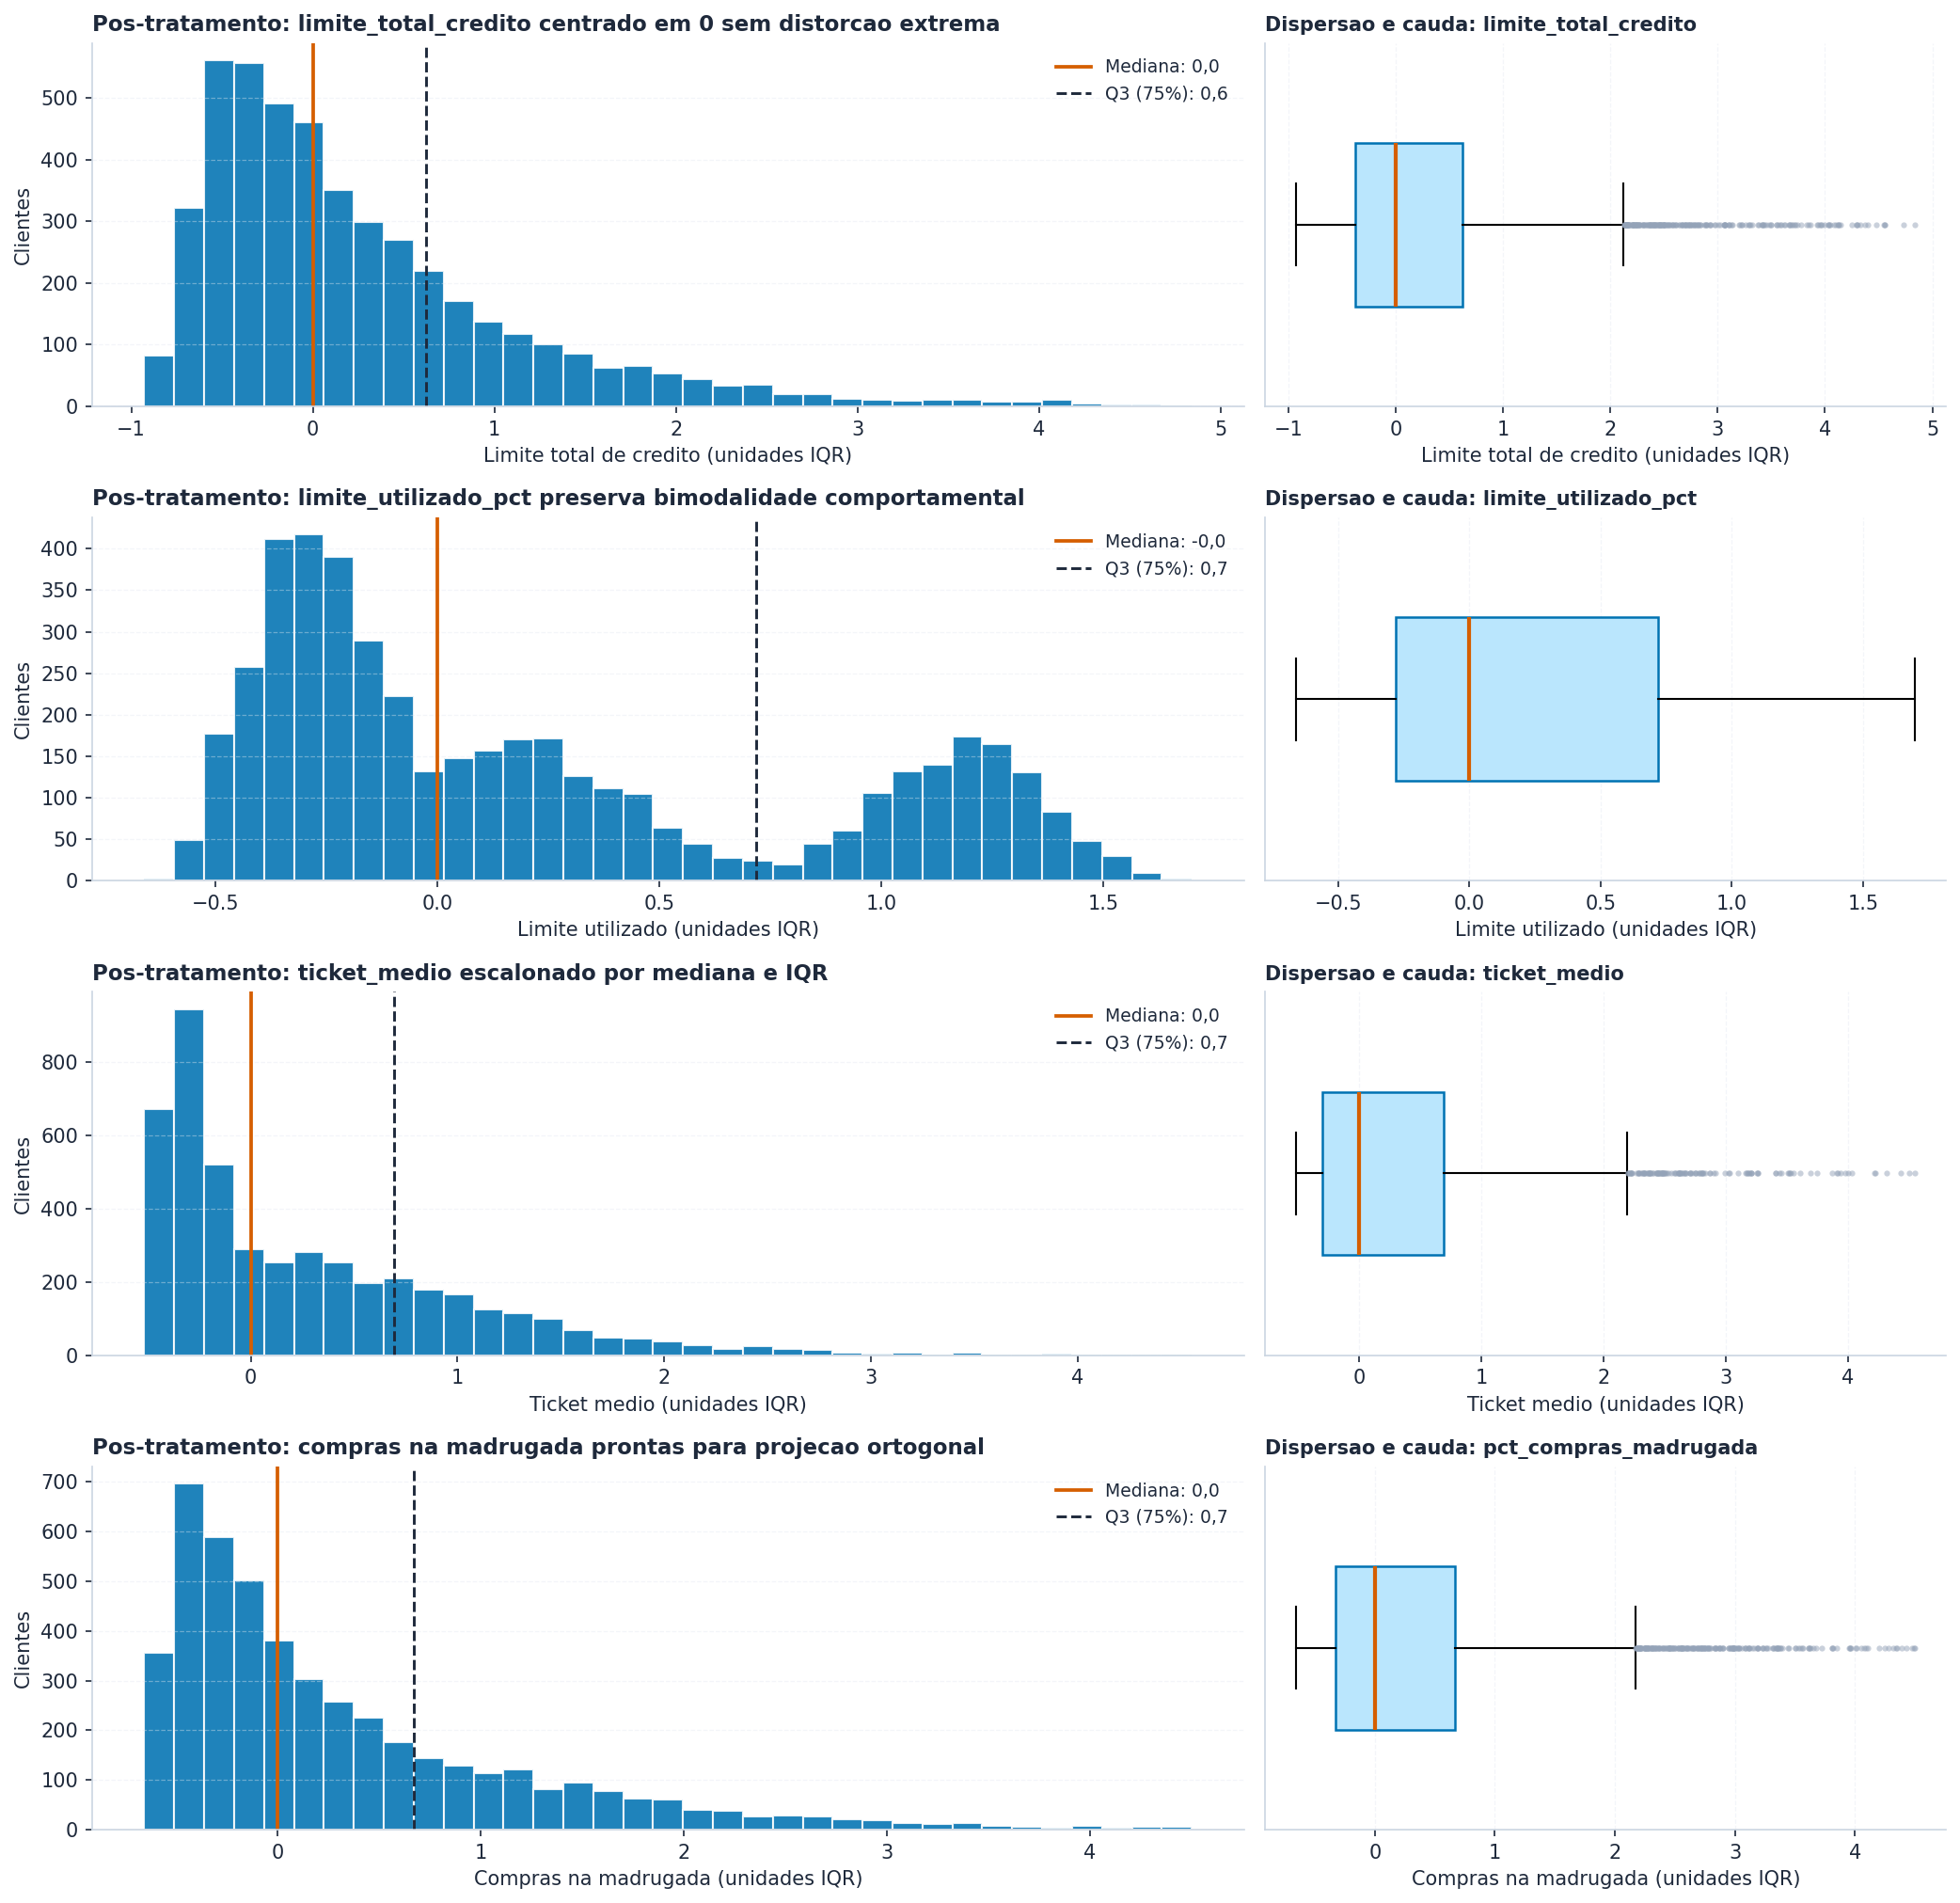

In [12]:
post_scale_specs = [
    ("limite_total_credito", "Pos-tratamento: limite_total_credito centrado em 0 sem distorcao extrema", "Limite total de credito (unidades IQR)"),
    ("limite_utilizado_pct", "Pos-tratamento: limite_utilizado_pct preserva bimodalidade comportamental", "Limite utilizado (unidades IQR)"),
    ("ticket_medio", "Pos-tratamento: ticket_medio escalonado por mediana e IQR", "Ticket medio (unidades IQR)"),
    ("pct_compras_madrugada", "Pos-tratamento: compras na madrugada prontas para projecao ortogonal", "Compras na madrugada (unidades IQR)"),
]
util.plot_hist_and_box(df_scaled, post_scale_specs, save_path="../reports/figures/fig06b_pos_tratamento_distribuicoes.png")

df_no_outliers.to_csv("../data/base04_cartao_limpa.csv", index=False)
df_no_outliers.to_csv("../data/processed/base04_cartao_limpa.csv", index=False)
df_scaled.to_csv("../data/processed/base04_cartao_limpa_escalonada.csv", index=False)
print("Bases limpas salvas em data/base04_cartao_limpa.csv e data/processed/")

### 4.5 Redução de Dimensionalidade com PCA (Análise de Componentes Principais)

Mesmo após a remoção das 8 variáveis colineares, o conjunto escalonado contém 38 colunas (26 numéricas e 12 binárias do One-Hot Encoding). Aplicamos a **Análise de Componentes Principais (PCA)** para projetar os dados em um subespaço ortogonal de baixa dimensão.

#### O que escolhemos e por que não escolhemos outra técnica de redução
- **Por que escolhemos PCA com 3 Componentes Principais**: Em espaços de alta dimensão (38 atributos), ocorre a *maldição da dimensionalidade*: o volume do espaço cresce exponencialmente e as distâncias euclidianas entre pares de pontos tornam-se quase uniformes, prejudicando tanto a partição por centróides (K-Means) quanto a estimativa de densidade local em hiperesferas de raio $\varepsilon$ (DBSCAN). Os **3 primeiros componentes principais** retêm **$64,43\%$ da variância total** da base (e os 4 primeiros retêm $75,18\%$), concentrando os eixos estruturais de alavancagem/saques (PC1: $35,05\%$), volume de uso/compras noturnas (PC2: $17,26\%$) e frequência transacional/pagamento mínimo (PC3: $12,11\%$) enquanto descartam o ruído esparso das dimensões residuais.
- **Por que NÃO escolhemos t-SNE ou UMAP para alimentar os clusters**: O t-SNE e o UMAP são técnicas não lineares estocásticas projetadas para visualização gráfica. Eles alteram as distâncias globais entre grupos e criam aglomerações artificiais dependentes do hiperparâmetro `perplexity` ou `n_neighbors`, o que invalida o uso direto de algoritmos baseados em densidade real (DBSCAN) ou covariância gaussiana (GMM).

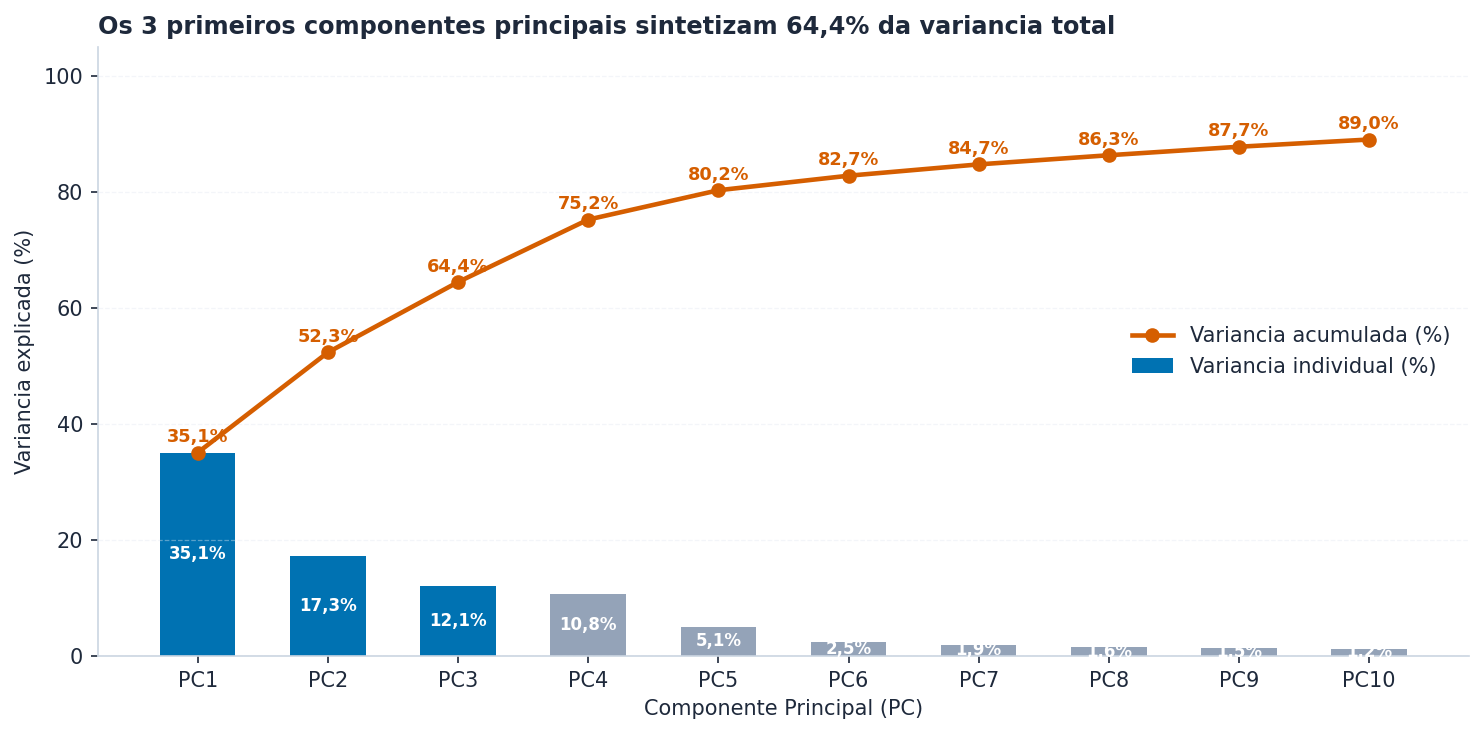

,PC1,PC2,PC3
limite_total_credito,0.1004,0.2479,-0.3795
limite_utilizado_pct,-0.1465,0.2395,0.1016
gasto_maximo_unico,0.2454,-0.0530,-0.0752
qtd_transacoes_30d,0.1355,-0.1053,0.4078
qtd_estornos_12m,-0.1237,0.2449,0.0399
valor_estornos_12m,-0.1984,-0.0054,0.2730
dias_desde_ultimo_atraso,-0.2325,-0.0465,-0.0867
pct_pagamento_minimo,0.0388,0.0079,0.4686
pct_pagamento_total_fatura,0.1922,0.1470,-0.0101
qtd_parcelamentos_12m,-0.1901,0.1743,0.0254


In [13]:
full_pca = PCA(random_state=42)
full_pca.fit(df_scaled)

var_ratio = full_pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_ratio)
n_show = 10
n_components = 3
x_idx = np.arange(1, n_show + 1)

fig, ax = plt.subplots(figsize=(10, 5))
bar_colors = [util.COLOR_HIGHLIGHT if i < n_components else util.COLOR_NEUTRAL for i in range(n_show)]
ax.bar(x_idx, var_ratio[:n_show], color=bar_colors, width=0.58, label="Variancia individual (%)")
ax.plot(x_idx, cum_var[:n_show], color=util.COLOR_ALERT, marker="o", linewidth=2.2, label="Variancia acumulada (%)")

for i in range(n_show):
    ax.text(x_idx[i], cum_var[i] + 1.8, f"{cum_var[i]:.1f}%".replace(".", ","), ha="center", fontsize=8.5, color=util.COLOR_ALERT, fontweight="bold")
    ax.text(x_idx[i], var_ratio[i] / 2, f"{var_ratio[i]:.1f}%".replace(".", ","), ha="center", va="center", fontsize=8, color="white", fontweight="bold")

ax.set_title(f"Os {n_components} primeiros componentes principais sintetizam {cum_var[n_components-1]:.1f}% da variancia total".replace(".", ","), loc="left", fontsize=11.5)
ax.set_xlabel("Componente Principal (PC)")
ax.set_ylabel("Variancia explicada (%)")
ax.set_xticks(x_idx)
ax.set_xticklabels([f"PC{i}" for i in x_idx])
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="center right")
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
fig.savefig("../reports/figures/fig07_pca_variancia_explicada.png")
plt.show()

pca_model = PCA(n_components=n_components, random_state=42)
X_pca = pca_model.fit_transform(df_scaled)

pca_loadings = pd.DataFrame(
    pca_model.components_.T,
    index=df_scaled.columns,
    columns=[f"PC{i+1}" for i in range(n_components)],
).round(4)
pca_loadings.head(15)

## 5. Etapa de Mineração de Dados (KDD): Modelagem Não Supervisionada

Implementamos e comparamos três algoritmos pertencentes a paradigmas distintos de aprendizado não supervisionado:
1. **K-Means (Paradigma Particional — Baseline)**: estabelece a partição rígida inicial por minimização da variância intracluster.
2. **DBSCAN (Paradigma Baseado em Densidade — Detecção de Fraudes)**: isola anomalias multivariadas em regiões de baixa densidade (`cluster = -1`) sem forçar sua inclusão em perfis legítimos.
3. **GMM — *Gaussian Mixture Models* (Paradigma Probabilístico — Segmentação de Clientes)**: modela perfis elípticos com matriz de covariância completa e estima a probabilidade de cada cliente pertencer simultaneamente a mais de um perfil de consumo.

### 5.1 Baseline: K-Means e Método do Cotovelo

Executamos o K-Means variando $k$ de $2$ a $8$ para inspecionar a curva de inércia intracluster (WCSS — Método do Cotovelo), o coeficiente de Silhouette, o índice de Davies-Bouldin e o índice de Calinski-Harabasz.

#### Justificativa técnica do Baseline
- **Escolha de $k = 4$**: Na curva WCSS, a redução de inércia desacelera de forma acentuada em $k = 4$ (inércia de $14,96$ mil), ponto em que o índice de **Calinski-Harabasz atinge seu máximo global ($4.244,4$)** com Silhouette de $0,4183$ e grupos equilibrados ($1.241$, $1.076$, $1.176$ e $1.151$ clientes).
- **Por que o K-Means é apenas o Baseline**: O K-Means impõe fronteiras lineares de Voronoi (assumindo grupos esféricos de mesmo raio) e atribui $100\%$ dos registros a algum centróide (*hard clustering*). Com isso, clientes com comportamento fraudulento ou híbrido são absorvidos pelos grupos comuns.

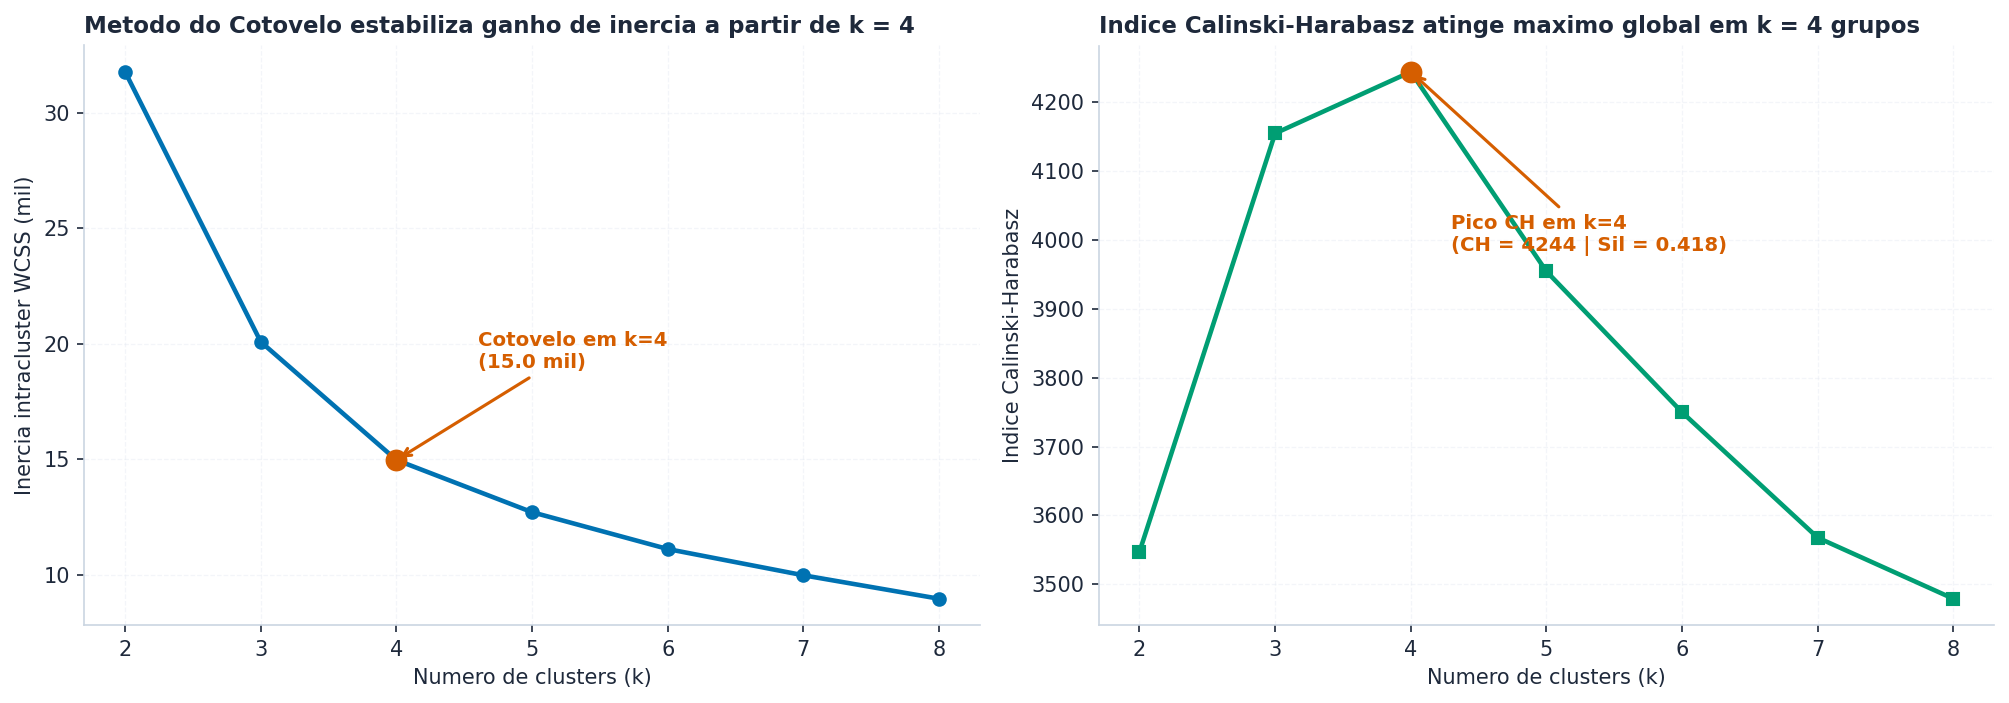

,k,wcss_inertia,silhouette,davies_bouldin,calinski_harabasz
0,2,31761.0,0.4488,0.8222,3547.1
1,3,20078.5,0.4428,0.8927,4155.0
2,4,14964.5,0.4183,0.8796,4244.4
3,5,12706.1,0.4044,0.9122,3954.5
4,6,11111.7,0.3590,1.0263,3749.8
5,7,9976.5,0.3212,1.0967,3567.6
6,8,8960.8,0.3147,1.1042,3478.9


In [14]:
k_range = range(2, 9)
best_k = 4
kmeans_records = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbls = km.fit_predict(X_pca)
    m = util.calculate_clustering_metrics(X_pca, lbls, f"K-Means (k={k})")
    m["k"] = k
    m["wcss_inertia"] = round(float(km.inertia_), 1)
    kmeans_records.append(m)

kmeans_eval_df = pd.DataFrame(kmeans_records)[["k", "wcss_inertia", "silhouette", "davies_bouldin", "calinski_harabasz"]]

fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.8))
axs[0].plot(kmeans_eval_df["k"], kmeans_eval_df["wcss_inertia"] / 1000.0, marker="o", color=util.COLOR_HIGHLIGHT, linewidth=2.2)
best_row = kmeans_eval_df[kmeans_eval_df["k"] == best_k].iloc[0]
axs[0].scatter([best_k], [best_row["wcss_inertia"] / 1000.0], color=util.COLOR_ALERT, s=90, zorder=5)
axs[0].annotate(
    f"Cotovelo em k={best_k}\n({best_row['wcss_inertia']/1000.0:.1f} mil)",
    xy=(best_k, best_row["wcss_inertia"] / 1000.0),
    xytext=(best_k + 0.6, best_row["wcss_inertia"] / 1000.0 + 4.0),
    arrowprops={"arrowstyle": "->", "color": util.COLOR_ALERT, "lw": 1.5},
    fontsize=9.5,
    fontweight="bold",
    color=util.COLOR_ALERT,
)
axs[0].set_title("Metodo do Cotovelo estabiliza ganho de inercia a partir de k = 4", loc="left", fontsize=11)
axs[0].set_xlabel("Numero de clusters (k)")
axs[0].set_ylabel("Inercia intracluster WCSS (mil)")
axs[0].set_xticks(list(k_range))
axs[0].grid(True, alpha=0.4)

axs[1].plot(kmeans_eval_df["k"], kmeans_eval_df["calinski_harabasz"], marker="s", color="#009E73", linewidth=2.2)
axs[1].scatter([best_k], [best_row["calinski_harabasz"]], color=util.COLOR_ALERT, s=90, zorder=5)
axs[1].annotate(
    f"Pico CH em k={best_k}\n(CH = {best_row['calinski_harabasz']:.0f} | Sil = {best_row['silhouette']:.3f})",
    xy=(best_k, best_row["calinski_harabasz"]),
    xytext=(best_k + 0.3, best_row["calinski_harabasz"] - 260),
    arrowprops={"arrowstyle": "->", "color": util.COLOR_ALERT, "lw": 1.5},
    fontsize=9.5,
    fontweight="bold",
    color=util.COLOR_ALERT,
)
axs[1].set_title("Indice Calinski-Harabasz atinge maximo global em k = 4 grupos", loc="left", fontsize=11)
axs[1].set_xlabel("Numero de clusters (k)")
axs[1].set_ylabel("Indice Calinski-Harabasz")
axs[1].set_xticks(list(k_range))
axs[1].grid(True, alpha=0.4)

plt.tight_layout()
fig.savefig("../reports/figures/fig08_kmeans_cotovelo.png")
plt.show()

kmeans_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_pca)
kmeans_summary = util.calculate_clustering_metrics(X_pca, kmeans_labels, "K-Means (Baseline k=4)")
df_orig_valid["kmeans_cluster"] = kmeans_labels

kmeans_eval_df

### 5.2 Detecção de Possíveis Fraudes por Densidade: DBSCAN

Aplicamos o **DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*)** sobre o espaço dos 3 componentes principais para identificar clientes cujo padrão combinado de transações, saques, estornos e horários se afasta das regiões densas da carteira.

#### O que escolhemos e por que não escolhemos outro algoritmo para anomalias
- **Por que escolhemos DBSCAN**: Diferentemente do K-Means e da clusterização hierárquica aglomerativa (que obrigam todos os pontos a pertencerem a um grupo e possuem custo quadrático/cúbico), o DBSCAN define grupos como regiões contínuas de alta densidade separadas por vazios. Pontos que não possuem pelo menos `min_samples` vizinhos dentro de um raio $\varepsilon$ recebem o rótulo `-1` (ruído/anomalia), funcionando diretamente como um detector não supervisionado de suspeitas de fraude.
- **Calibração dos hiperparâmetros (`min_samples = 15`, `eps = 0,75`)**: Seguindo a heurística de dimensões ($\text{min\_samples} \ge 2 \cdot d$, ajustado para $15$ a fim de garantir robustez estatística em $N = 4.644$), traçamos a curva *k-distance* (distância ao 15º vizinho mais próximo ordenada). O joelho de ascensão vertical ocorre em $\varepsilon = 0,75$, isolando **232 clientes ($5,00\%$ da base filtrada)** como anomalias de baixa densidade (`cluster = -1`).

Contagem por rotulo no DBSCAN (-1 = suspeita de fraude / anomalia):
 1    3415
 0     997
-1     232


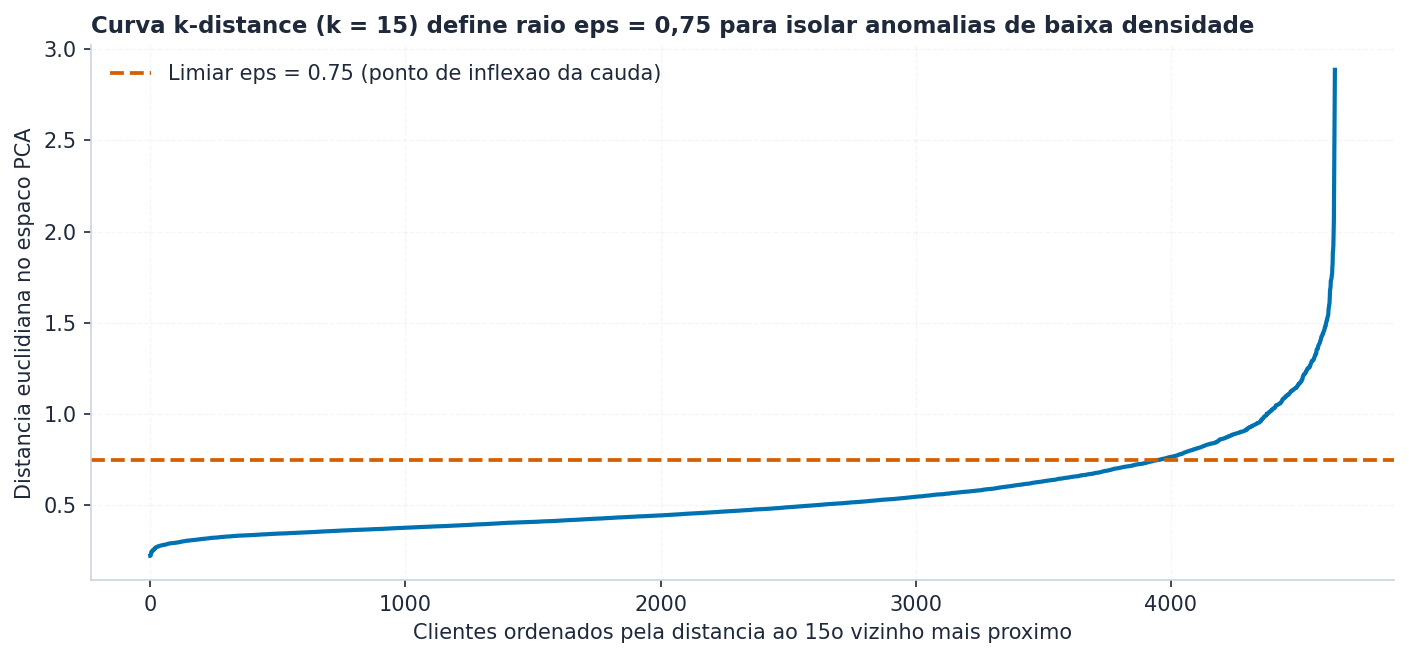

,Valor_DBSCAN
n_clusters_densos,2.0000
qtd_ruidos_anomalias,232.0000
taxa_ruido_pct,5.0000
qtd_core_points,3960.0000
pct_core_points,85.2700
qtd_border_points,452.0000
silhouette_nucleos_densos,0.4637
silhouette_global_com_ruido,0.3895
davies_bouldin_nucleos,0.7692
calinski_harabasz_nucleos,3533.6000


In [15]:
min_samples = 15
eps = 0.75

nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances, _ = nbrs.kneighbors(X_pca)
k_dist = np.sort(distances[:, min_samples - 1])

fig, ax = plt.subplots(figsize=(9.5, 4.5))
ax.plot(np.arange(len(k_dist)), k_dist, color=util.COLOR_HIGHLIGHT, linewidth=2.0)
ax.axhline(eps, color=util.COLOR_ALERT, linestyle="--", linewidth=1.8, label=f"Limiar eps = {eps:.2f} (ponto de inflexao da cauda)")
ax.set_title(f"Curva k-distance (k = {min_samples}) define raio eps = {eps:.2f} para isolar anomalias de baixa densidade".replace(".", ","), loc="left", fontsize=11)
ax.set_xlabel("Clientes ordenados pela distancia ao 15o vizinho mais proximo")
ax.set_ylabel("Distancia euclidiana no espaco PCA")
ax.legend(frameon=False, loc="upper left")
ax.grid(True, alpha=0.4)

plt.tight_layout()
fig.savefig("../reports/figures/fig09_dbscan_kdistance.png")
plt.show()

dbscan_model = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan_model.fit_predict(X_pca)
dbscan_summary = util.calculate_clustering_metrics(X_pca, dbscan_labels, f"DBSCAN (eps={eps}, min_samples={min_samples})")
dbscan_detailed_metrics = util.evaluate_dbscan_metrics(X_pca, dbscan_model, min_samples=min_samples)
df_orig_valid["dbscan_cluster"] = dbscan_labels

print("Contagem por rotulo no DBSCAN (-1 = suspeita de fraude / anomalia):")
print(pd.Series(dbscan_labels).value_counts().to_string())
pd.DataFrame([dbscan_detailed_metrics]).T.rename(columns={0: "Valor_DBSCAN"})

### 5.3 Segmentação Probabilística de Clientes: Gaussian Mixture Models (GMM)

Para segmentar os perfis de consumo da operadora, utilizamos o **Modelo de Mistura Gaussiana (GMM)** com matriz de covariância livre (`covariance_type="full"`), avaliando de $2$ a $8$ componentes pelo Critério de Informação Bayesiano (BIC), Critério de Informação de Akaike (AIC), Log-Verossimilhança Média (*Mean Log-Likelihood*), Entropia de Shannon das probabilidades a posteriori, Certeza Média de Pertencimento e métricas geométricas (Silhouette, Davies-Bouldin e Calinski-Harabasz).

#### O que escolhemos e por que o GMM supera o K-Means na segmentação bancária
- **Agrupamento Probabilístico (*Soft Clustering*)**: No setor de cartões, um cliente raramente pertence de forma estática e exclusiva a um único perfil; ele pode apresentar $60\%$ de aderência ao perfil de compras cotidianas e $40\%$ ao perfil de parcelamento digital. Enquanto o K-Means entrega apenas um rótulo binário ($0$ ou $1$), o algoritmo *Expectation-Maximization* (EM) do GMM estima a probabilidade condicional $P(c_k \mid x_i)$ de cada cliente pertencer a cada um dos $K$ componentes gaussianos.
- **Geometria Elíptica Flexível**: O K-Means equivale a um caso restrito do GMM com matrizes de covariância identidades esféricas ($\Sigma_k = \sigma^2 I$). Ao utilizar `covariance_type="full"`, cada cluster no GMM assume sua própria matriz de covariância $\Sigma_k$, adaptando-se a grupos alongados e correlacionados no espaço PCA.
- **Escolha de $k = 4$ pelo BIC**: O valor do BIC cai fortemente de $k=2$ ($53,13$ mil) até atingir seu ponto de inflexão mínimo em **$k = 4$ ($49,96$ mil)**, subindo em $k = 5$ ($49,99$ mil). Além disso, em $k = 4$ o GMM identifica **193 clientes em zona de transição comportamental** (cuja probabilidade máxima de pertencimento é inferior a $80\%$), permitindo ações comerciais e de limite sob medida para clientes híbridos.

Metricas Detalhadas do GMM Selecionado (k=4):
n_componentes                      4.0000
bic                            49963.7000
aic                            49712.4000
log_likelihood_media              -5.3439
entropia_media_shannon             0.0664
probabilidade_max_media            0.9756
clientes_alta_certeza_ge_80     4451.0000
clientes_transicao_lt_80         193.0000
taxa_transicao_pct                 4.1600
silhouette                         0.4095
davies_bouldin                     0.9074
calinski_harabasz               4124.7000


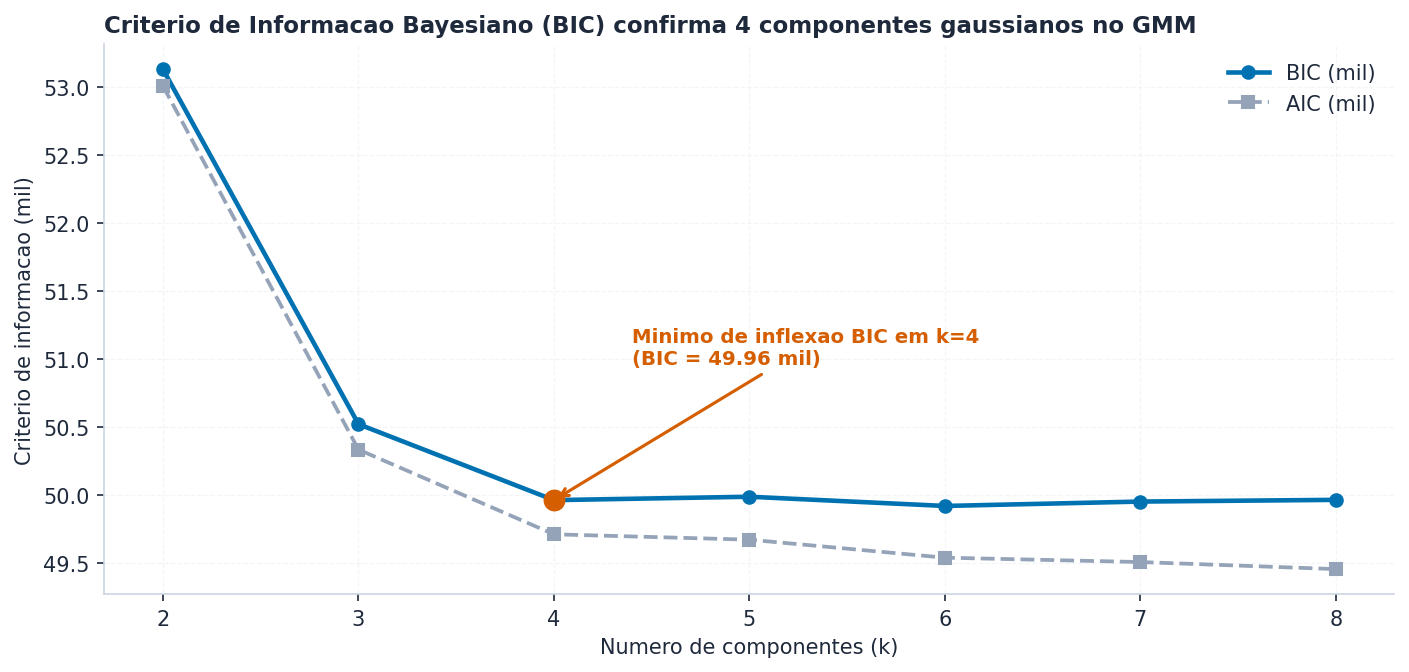

,n_componentes,bic,aic,log_likelihood_media,entropia_media_shannon,probabilidade_max_media,clientes_alta_certeza_ge_80,clientes_transicao_lt_80,taxa_transicao_pct,silhouette,davies_bouldin,calinski_harabasz
0,2,53129.7,53007.3,-5.7030,0.0118,0.9960,4615,29,0.62,0.4505,0.8097,3525.0
1,3,50522.1,50335.2,-5.4131,0.0213,0.9927,4594,50,1.08,0.4441,0.8813,4098.0
2,4,49963.7,49712.4,-5.3439,0.0664,0.9756,4451,193,4.16,0.4095,0.9074,4124.7
3,5,49988.6,49672.9,-5.3375,0.1714,0.9303,3975,669,14.41,0.3659,0.9630,3461.9
4,6,49920.8,49540.7,-5.3211,0.2602,0.8913,3558,1086,23.39,0.3623,0.9735,3349.1
5,7,49953.1,49508.5,-5.3155,0.3771,0.8334,2887,1757,37.83,0.3159,1.0609,3290.7
6,8,49965.7,49456.6,-5.3078,0.4739,0.7922,2472,2172,46.77,0.3028,1.0795,3251.1


In [16]:
gmm_records = []
for k in k_range:
    gmm = GaussianMixture(n_components=k, covariance_type="full", random_state=42, n_init=5)
    lbls = gmm.fit_predict(X_pca)
    probs = gmm.predict_proba(X_pca)
    m_gmm = util.evaluate_gmm_metrics(X_pca, gmm, lbls, probs)
    gmm_records.append(m_gmm)

gmm_eval_df = pd.DataFrame(gmm_records)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(gmm_eval_df["n_componentes"], gmm_eval_df["bic"] / 1000.0, marker="o", color=util.COLOR_HIGHLIGHT, linewidth=2.2, label="BIC (mil)")
ax.plot(gmm_eval_df["n_componentes"], gmm_eval_df["aic"] / 1000.0, marker="s", color=util.COLOR_NEUTRAL, linewidth=1.8, linestyle="--", label="AIC (mil)")
best_gmm_row = gmm_eval_df[gmm_eval_df["n_componentes"] == best_k].iloc[0]
ax.scatter([best_k], [best_gmm_row["bic"] / 1000.0], color=util.COLOR_ALERT, s=90, zorder=5)
ax.annotate(
    f"Minimo de inflexao BIC em k={best_k}\n(BIC = {best_gmm_row['bic']/1000.0:.2f} mil)",
    xy=(best_k, best_gmm_row["bic"] / 1000.0),
    xytext=(best_k + 0.4, best_gmm_row["bic"] / 1000.0 + 1.0),
    arrowprops={"arrowstyle": "->", "color": util.COLOR_ALERT, "lw": 1.5},
    fontsize=9.5,
    fontweight="bold",
    color=util.COLOR_ALERT,
)
ax.set_title("Criterio de Informacao Bayesiano (BIC) confirma 4 componentes gaussianos no GMM", loc="left", fontsize=11)
ax.set_xlabel("Numero de componentes (k)")
ax.set_ylabel("Criterio de informacao (mil)")
ax.set_xticks(list(k_range))
ax.legend(frameon=False, loc="upper right")
ax.grid(True, alpha=0.4)

plt.tight_layout()
fig.savefig("../reports/figures/fig10_gmm_bic_aic.png")
plt.show()

gmm_model = GaussianMixture(n_components=best_k, covariance_type="full", random_state=42, n_init=5)
gmm_labels = gmm_model.fit_predict(X_pca)
gmm_probs = gmm_model.predict_proba(X_pca)
gmm_max_prob = gmm_probs.max(axis=1)

gmm_detailed_metrics = util.evaluate_gmm_metrics(X_pca, gmm_model, gmm_labels, gmm_probs)
gmm_summary = util.calculate_clustering_metrics(
    X_pca,
    gmm_labels,
    "GMM (k=4, full covariance)",
    extra_count=int((gmm_max_prob < 0.80).sum()),
)

df_orig_valid["gmm_cluster"] = gmm_labels
df_orig_valid["gmm_prob_max"] = gmm_max_prob.round(4)
for k in range(best_k):
    df_orig_valid[f"gmm_prob_c{k}"] = gmm_probs[:, k].round(4)

print("Metricas Detalhadas do GMM Selecionado (k=4):")
print(pd.Series(gmm_detailed_metrics).to_string())
gmm_eval_df

## 6. Etapa de Interpretação e Avaliação (KDD): Resultados e Discussão

### 6.1 Comparação Quantitativa e Visual dos Três Modelos

Reunimos na tabela abaixo as métricas internas de validação (Silhouette, Davies-Bouldin e Calinski-Harabasz) e a contagem de anomalias/transições detectadas pelas três abordagens no espaço reduzido pelo PCA. Em seguida, projetamos os resultados no plano formado pelos dois primeiros componentes principais (`PC1 x PC2`, que juntos explicam $52,31\%$ da variância total).

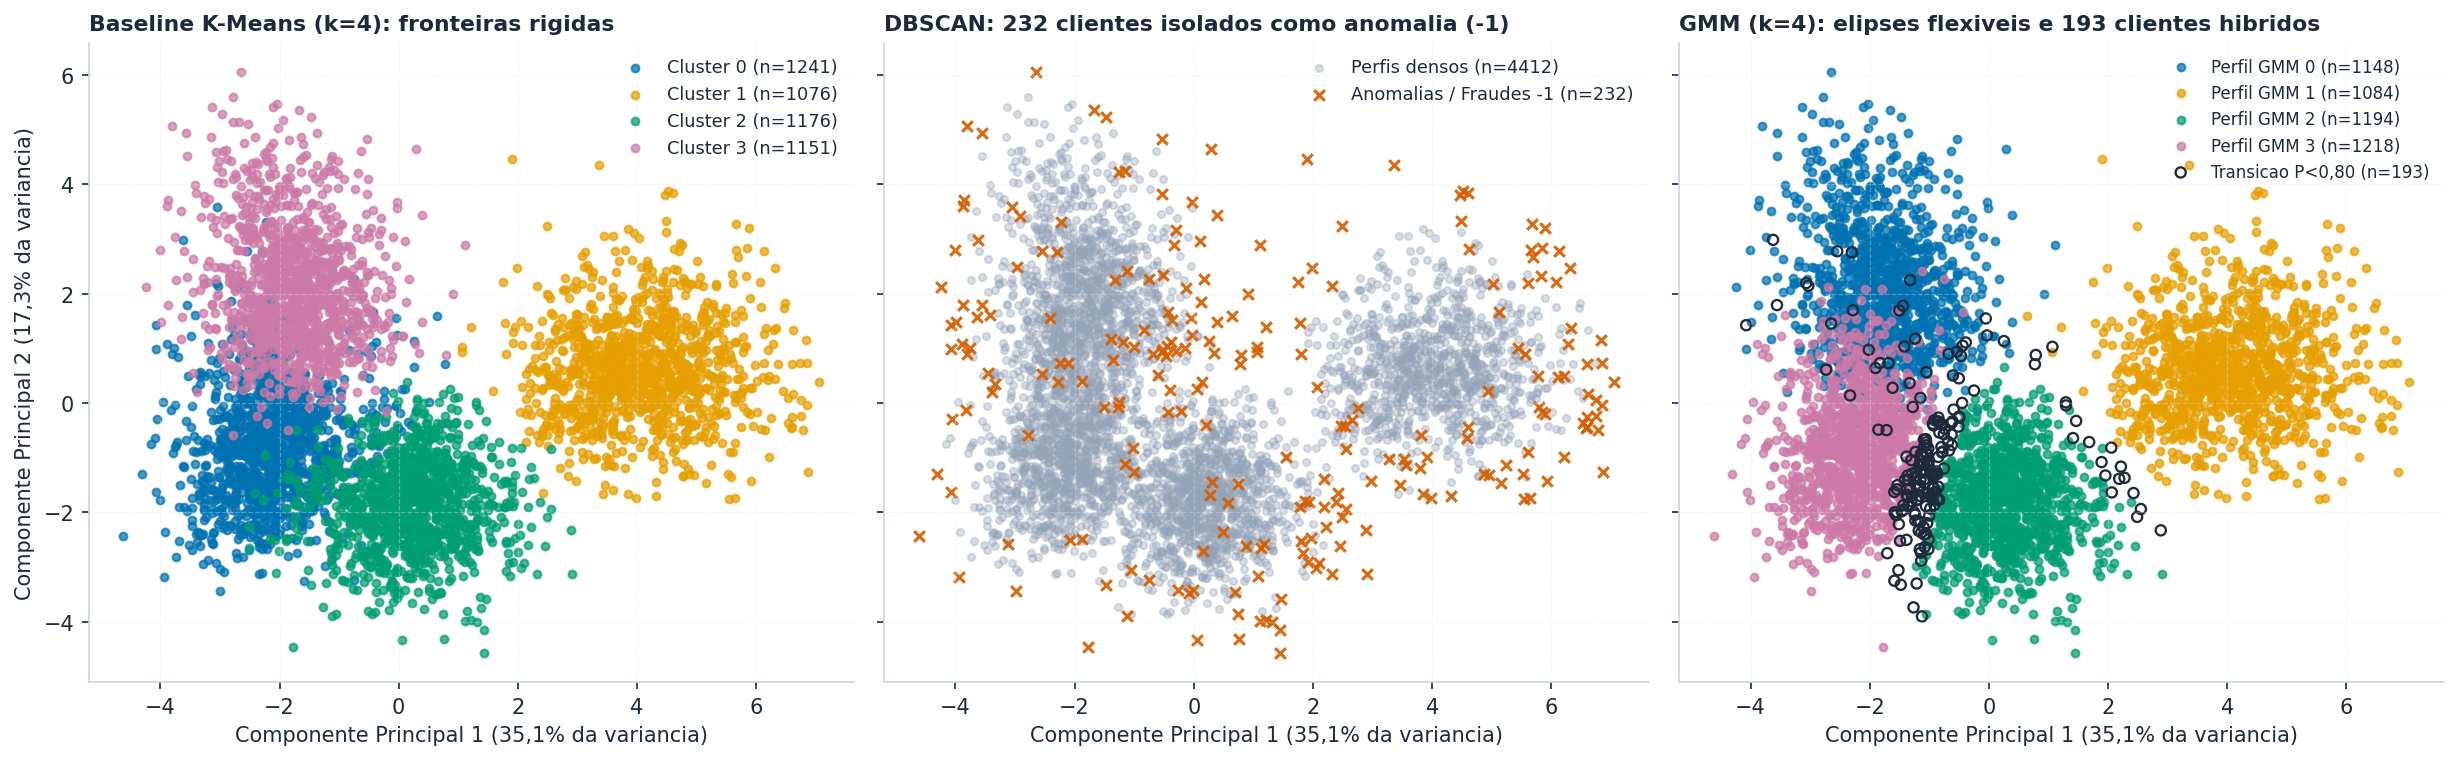

,algoritmo,n_clusters,silhouette,davies_bouldin,calinski_harabasz,ruidos_ou_transicao
0,K-Means (Baseline k=4),4,0.4183,0.8796,4244.4,0
1,"DBSCAN (eps=0.75, min_samples=15)",2,0.4637,0.7692,3533.6,232
2,"GMM (k=4, full covariance)",4,0.4095,0.9074,4124.7,193


In [17]:
comparison_df = pd.DataFrame([kmeans_summary, dbscan_summary, gmm_summary])

fig, axs = plt.subplots(1, 3, figsize=(16.5, 5.2), sharex=True, sharey=True)

for k in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == k
    axs[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.72, color=util.PALETTE_MAIN[k % len(util.PALETTE_MAIN)], label=f"Cluster {k} (n={mask.sum()})")
axs[0].set_title("Baseline K-Means (k=4): fronteiras rigidas", loc="left", fontsize=10.5)
axs[0].set_xlabel("Componente Principal 1 (35,1% da variancia)")
axs[0].set_ylabel("Componente Principal 2 (17,3% da variancia)")
axs[0].legend(frameon=False, fontsize=8.5, loc="upper right")
axs[0].grid(True, alpha=0.35)

normal_mask = dbscan_labels != -1
noise_mask = dbscan_labels == -1
axs[1].scatter(X_pca[normal_mask, 0], X_pca[normal_mask, 1], s=12, alpha=0.35, color=util.COLOR_NEUTRAL, label=f"Perfis densos (n={normal_mask.sum()})")
axs[1].scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], s=26, alpha=0.92, color=util.COLOR_ALERT, marker="x", label=f"Anomalias / Fraudes -1 (n={noise_mask.sum()})")
axs[1].set_title("DBSCAN: 232 clientes isolados como anomalia (-1)", loc="left", fontsize=10.5)
axs[1].set_xlabel("Componente Principal 1 (35,1% da variancia)")
axs[1].legend(frameon=False, fontsize=8.5, loc="upper right")
axs[1].grid(True, alpha=0.35)

for k in sorted(np.unique(gmm_labels)):
    mask = (gmm_labels == k) & (gmm_max_prob >= 0.80)
    axs[2].scatter(X_pca[mask, 0], X_pca[mask, 1], s=14, alpha=0.72, color=util.PALETTE_MAIN[k % len(util.PALETTE_MAIN)], label=f"Perfil GMM {k} (n={(gmm_labels == k).sum()})")
uncertain_mask = gmm_max_prob < 0.80
axs[2].scatter(X_pca[uncertain_mask, 0], X_pca[uncertain_mask, 1], s=24, facecolors="none", edgecolors=util.COLOR_DARK, linewidths=1.1, label=f"Transicao P<0,80 (n={uncertain_mask.sum()})")
axs[2].set_title("GMM (k=4): elipses flexiveis e 193 clientes hibridos", loc="left", fontsize=10.5)
axs[2].set_xlabel("Componente Principal 1 (35,1% da variancia)")
axs[2].legend(frameon=False, fontsize=8, loc="upper right")
axs[2].grid(True, alpha=0.35)

plt.tight_layout()
fig.savefig("../reports/figures/fig11_comparacao_clusters_pca2d.png")
plt.show()

comparison_df